## CheckIA – Auditor Inteligente de Datos Públicos

CheckIA es un proyecto orientado al análisis automatizado de datos públicos mediante técnicas de ciencia de datos e inteligencia artificial. Su propósito es identificar patrones, inconsistencias y áreas de mejora dentro de información gubernamental o institucional, facilitando diagnósticos rápidos y confiables. A través de un flujo optimizado que integra limpieza, procesamiento, visualización y generación de reportes, la herramienta permite una comprensión profunda de los datos y apoya la toma de decisiones basadas en evidencia.

from IPython.display import Image
Image(filename="C:\\Users\\cancu\\Documents\\GitHub\\Datapatrominio _CHECK_IA\\eu.png")


In [1]:
!pip install jupyterlab_widgets


## 📘 Dataset S1 – Declaraciones Patrimoniales y de Intereses

El Dataset S1 reúne la información completa de las declaraciones patrimoniales, de intereses y constancias de modificación que presentan las personas servidoras públicas de todas las entidades federativas de México, conforme a la Ley General de Responsabilidades Administrativas. Su estructura está organizada por estado, donde cada entidad contiene un archivo `completo.json.gz` que integra decenas de miles de registros con datos patrimoniales detallados: bienes inmuebles, vehículos, inversiones, adeudos, ingresos anuales, historial académico, trayectoria laboral, datos generales, información de dependientes económicos y tipo de declaración (inicio, modificación o conclusión). Este nivel de detalle permite rastrear la evolución financiera de cada persona a lo largo del tiempo.

El valor analítico del Dataset S1 es crucial para proyectos anticorrupción como **DataPatrimonio CHECK IA**, ya que permite identificar incrementos patrimoniales inusuales, variaciones significativas entre años y discrepancias entre ingresos declarados y adquisición de bienes. Al estar segmentado por entidad federativa y contener datos estandarizados, el dataset facilita la comparación entre servidores públicos, el cruce con información de contrataciones públicas (S6), participación en procedimientos (S2) y antecedentes de sanciones (S3). En conjunto, S1 constituye la base para detectar posibles indicadores de riesgo, anomalías financieras y patrones patrimoniales que podrían estar relacionados con conductas irregulares.


In [4]:
import os
import ipywidgets as widgets
widgets.Dropdown(options=['OK'])

# Ruta EXACTA hacia el archivo S1
s1_path = r"C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S1-Data json.gz"

def tree(dir_path, indent=""):
    """Imprime estructura estilo árbol (solo si es carpeta)."""
    items = sorted(os.listdir(dir_path))
    for index, item in enumerate(items):
        path = os.path.join(dir_path, item)
        connector = "└── " if index == len(items)-1 else "├── "
        print(indent + connector + item)
        if os.path.isdir(path):
            extension = "    " if index == len(items)-1 else "│   "
            tree(path, indent + extension)

# Mostrar resultado
print("📁 Verificando ruta del Dataset S1...\n")

if not os.path.exists(s1_path):
    print("❌ La ruta NO existe:\n", s1_path)

elif os.path.isfile(s1_path):
    print("📄 El Dataset S1 es un archivo (.json.gz):")
    print("Nombre del archivo:", os.path.basename(s1_path))

elif os.path.isdir(s1_path):
    print("📂 El Dataset S1 es una carpeta. Mostrando estructura:\n")
    tree(s1_path)


📁 Verificando ruta del Dataset S1...

📂 El Dataset S1 es una carpeta. Mostrando estructura:

├── Entidades Federativas
│   ├── Aguascalientes
│   │   └── completo.json.gz
│   ├── BajaCalifornia
│   │   └── completo.json.gz
│   ├── Bajacaliforniasur
│   │   └── completo.json.gz
│   ├── Campeche
│   │   └── completo.json.gz
│   ├── Chiapas
│   │   └── completo.json.gz
│   ├── Chihuahua
│   │   └── completo.json.gz
│   ├── Colima
│   │   └── completo.json.gz
│   ├── Edomex
│   │   └── completo.json.gz
│   ├── Guanajuato
│   │   └── completo.json.gz
│   ├── Guerrero
│   │   └── completo.json.gz
│   ├── Jalisco
│   │   └── completo.json.gz
│   ├── Michoacan
│   │   └── completo.json.gz
│   ├── Morelos
│   │   └── completo.json.gz
│   ├── Nayarit
│   │   └── completo.json.gz
│   ├── Puebla
│   │   └── completo.json.gz
│   ├── Quintanaroo
│   │   └── completo.json.gz
│   ├── Sanluispotosi
│   │   └── completo.json.gz
│   ├── Sinaloa
│   │   └── completo.json.gz
│   ├── Tabasco
│   ├── Tlaxcal

In [5]:
import os
import gzip
import json
import ipywidgets as widgets
widgets.Dropdown(options=['OK'])

# Ruta base del Dataset S1
BASE_S1 = r"C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S1-Data json.gz\Entidades Federativas"

# Obtener lista de entidades
try:
    entidades = [d for d in os.listdir(BASE_S1) if os.path.isdir(os.path.join(BASE_S1, d))]
except FileNotFoundError:
    entidades = []

print("📍 ENTIDADES DISPONIBLES EN S1:\n")
for i, e in enumerate(entidades, start=1):
    print(f"{i}. {e}")

# Selección por número
opcion = int(input("\n👉 Ingresa el número de la entidad a visualizar: "))

if opcion < 1 or opcion > len(entidades):
    print("❌ Opción inválida.")
else:
    entidad = entidades[opcion - 1]
    file_path = os.path.join(BASE_S1, entidad, "completo.json.gz")

    print(f"\n📂 Entidad seleccionada: {entidad}")
    print(f"📄 Archivo: {file_path}\n")

    if not os.path.exists(file_path):
        print("❌ No existe completo.json.gz dentro de esta entidad.")
    else:
        print("✔ Archivo encontrado. Cargando...\n")

        try:
            with gzip.open(file_path, "rt", encoding="utf-8") as f:
                data = json.load(f)

            print("🔍 Tipo de objeto raíz:", type(data))

            if isinstance(data, list):
                print(f"📌 Total de registros: {len(data)}\n")
                print("Primer registro:\n")
                print(json.dumps(data[0], indent=2, ensure_ascii=False)[:2000])

            elif isinstance(data, dict):
                print("🔑 Claves del diccionario:", list(data.keys()))
                print(json.dumps(data, indent=2, ensure_ascii=False)[:2000])

        except Exception as e:
            print("❌ Error leyendo el archivo:", e)


📍 ENTIDADES DISPONIBLES EN S1:

1. Aguascalientes
2. BajaCalifornia
3. Bajacaliforniasur
4. Campeche
5. Chiapas
6. Chihuahua
7. Colima
8. Edomex
9. Guanajuato
10. Guerrero
11. Jalisco
12. Michoacan
13. Morelos
14. Nayarit
15. Puebla
16. Quintanaroo
17. Sanluispotosi
18. Sinaloa
19. Tabasco
20. Tlaxcala
21. Zacatecas



📂 Entidad seleccionada: BajaCalifornia
📄 Archivo: C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S1-Data json.gz\Entidades Federativas\BajaCalifornia\completo.json.gz

✔ Archivo encontrado. Cargando...

🔍 Tipo de objeto raíz: <class 'list'>
📌 Total de registros: 11627

Primer registro:

{
  "_id": "66e9d76265fa10a005d8c5a7",
  "id": "66e9d76265fa10a005d8c5a7",
  "metadata": {
    "actualizacion": "2021-05-31T00:00:00Z",
    "institucion": "SECRETARIA EJECUTIVA DEL SISTEMA ESTATAL ANTICORRUPCION",
    "declaracionCompleta": false,
    "actualizacionConflictoInteres": false,
    "tipo": "INICIAL"
  },
  "declaracion": {
    "situacionPatrimonial": {
      "datosGenerales": {
        "nombre": "NANCY",
        "primerApellido": "ALVARADO",
        "segundoApellido": "GIJON",
        "correoElectronico": {
          "institucional": "nancygijon@hotmail.com"
        }
      },
      "datosCurricularesDeclarante": {
        "escolaridad": []
      },
      "datosEmpleoCargoComisio

## 📂 Dataset S2 – Servidores Públicos que Intervienen en Procedimientos de Contratación

El Dataset S2 forma parte de la Plataforma Digital Nacional y concentra información detallada sobre los servidores públicos que participan directamente en los procesos de contratación pública. Incluye datos sobre su puesto, nivel jerárquico, tipo de participación, responsabilidades y relación con procedimientos como adquisiciones, concesiones, licitaciones y servicios. Su propósito es identificar a los actores clave dentro del ciclo de compras gubernamentales y permitir el análisis de posibles riesgos, conflictos de interés y patrones de intervención dentro de distintas dependencias federales, estatales y municipales.

La estructura del dataset está organizada por entidades federativas y organismos autónomos. Cada carpeta contiene múltiples archivos en formato JSON —algunos divididos en decenas de fragmentos— para representar miles de registros de servidores públicos. Este dataset es esencial para el proyecto **Datapatrimonio CHECK IA**, ya que permite vincular a los funcionarios con contratos (S6), declaraciones patrimoniales (S1) y sanciones (S3), posibilitando modelos de riesgo, redes jerárquicas y detección de anomalías en compras públicas.



In [6]:

# Ruta EXACTA hacia el dataset S2
s2_path = r"C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S2-Data"

def tree(dir_path, indent=""):
    """Imprime estructura de carpetas y archivos como árbol."""
    try:
        items = sorted(os.listdir(dir_path))
    except Exception as e:
        print(f"❌ Error al leer carpeta: {e}")
        return
    
    for index, item in enumerate(items):
        path = os.path.join(dir_path, item)
        connector = "└── " if index == len(items)-1 else "├── "
        
        print(indent + connector + item)
        
        if os.path.isdir(path):
            extension = "    " if index == len(items)-1 else "│   "
            tree(path, indent + extension)

print("📁 Verificando ruta del Dataset S2...\n")

if not os.path.exists(s2_path):
    print("❌ La ruta NO existe:\n", s2_path)

elif os.path.isfile(s2_path):
    print("⚠ La ruta corresponde a un ARCHIVO, no una carpeta.")
    print("Archivo detectado:", os.path.basename(s2_path))

elif os.path.isdir(s2_path):
    print("📂 Dataset S2 detectado como carpeta. Mostrando estructura completa:\n")
    tree(s2_path)


📁 Verificando ruta del Dataset S2...

📂 Dataset S2 detectado como carpeta. Mostrando estructura completa:

└── S2
    ├── SABG
    │   ├── servidores_1.json
    │   ├── servidores_10.json
    │   ├── servidores_11.json
    │   ├── servidores_12.json
    │   ├── servidores_13.json
    │   ├── servidores_14.json
    │   ├── servidores_15.json
    │   ├── servidores_16.json
    │   ├── servidores_17.json
    │   ├── servidores_18.json
    │   ├── servidores_19.json
    │   ├── servidores_2.json
    │   ├── servidores_20.json
    │   ├── servidores_21.json
    │   ├── servidores_22.json
    │   ├── servidores_23.json
    │   ├── servidores_24.json
    │   ├── servidores_25.json
    │   ├── servidores_26.json
    │   ├── servidores_27.json
    │   ├── servidores_28.json
    │   ├── servidores_29.json
    │   ├── servidores_3.json
    │   ├── servidores_30.json
    │   ├── servidores_31.json
    │   ├── servidores_32.json
    │   ├── servidores_33.json
    │   ├── servidores_34.json
    │   

## 📘 Descripción del Dataset S3 – Organización de Sanciones por Tipo y Entidad Federativa

El Dataset **S3-Data** presenta una estructura organizada en cuatro grandes categorías que corresponden a distintos tipos de faltas cometidas por personas servidoras públicas o particulares. Las carpetas incluyen: **faltas administrativas graves**, **faltas administrativas no graves**, **faltas graves cometidas por personas físicas**, y **faltas graves cometidas por personas morales**. Dentro de cada categoría, los archivos JSON están segmentados por entidad federativa (ej. Aguascalientes, BCS, Jalisco, Quintana Roo, Sinaloa, Veracruz, Zacatecas), así como archivos específicos de instituciones como el IFT. Cada archivo contiene información detallada sobre expedientes, autoridades responsables, descripción de hechos, tipo de falta cometida, sanciones económicas, inhabilitaciones, fechas de resolución y datos generales de la persona involucrada. Esta estructura permite analizar patrones de conducta y comparativas entre estados o tipos de faltas, facilitando un análisis más fino de sanciones en el ámbito público.

La segmentación del dataset es especialmente útil para el proyecto **DataPatrimonio CHECK IA**, ya que permite cruzar información de sanciones con otros sistemas como **S1 (Declaraciones Patrimoniales)** y **S6 (Contrataciones Públicas)**. A través de esta separación por tipo de falta, es posible identificar servidores públicos que incurren en conductas de riesgo, entidades con mayor incidencia de sanciones, empresas o personas morales sancionadas, y relaciones entre sanciones y procesos de contratación o incrementos patrimoniales atípicos. En conjunto, esta estructura robusta y bien organizada convierte al S3 en una pieza clave para el cálculo del **RiskScore SNA**, fortaleciendo la detección de alertas tempranas y patrones de posible corrupción dentro del análisis integral del patrimonio.


In [7]:
import os

# Ruta EXACTA hacia el dataset S3
s3_path = r"C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S3-Data"

def tree(dir_path, indent=""):
    """Imprime estructura de carpetas y archivos como árbol."""
    try:
        items = sorted(os.listdir(dir_path))
    except Exception as e:
        print(f"❌ Error al leer carpeta: {e}")
        return
    
    for index, item in enumerate(items):
        path = os.path.join(dir_path, item)
        connector = "└── " if index == len(items)-1 else "├── "
        
        print(indent + connector + item)
        
        if os.path.isdir(path):
            extension = "    " if index == len(items)-1 else "│   "
            tree(path, indent + extension)

print("📁 Verificando ruta del Dataset S3...\n")

if not os.path.exists(s3_path):
    print("❌ La ruta NO existe:\n", s3_path)

elif os.path.isfile(s3_path):
    print("⚠ La ruta corresponde a un ARCHIVO, no una carpeta.")
    print("Archivo detectado:", os.path.basename(s3_path))

elif os.path.isdir(s3_path):
    print("📂 Dataset S3 detectado como carpeta. Mostrando estructura completa:\n")
    tree(s3_path)


📁 Verificando ruta del Dataset S3...

📂 Dataset S3 detectado como carpeta. Mostrando estructura completa:

└── S3
    ├── faltas_administrativas_graves
    │   ├── data_SESEA_Aguascalientes.json
    │   ├── data_SESEA_BCS.json
    │   ├── data_SESEA_Chihuahua.json
    │   ├── data_SESEA_DURANGO.json
    │   ├── data_SESEA_EdoMex.json
    │   ├── data_SESEA_Guerrero.json
    │   ├── data_SESEA_Jalisco.json
    │   ├── data_SESEA_Michoacan.json
    │   ├── data_SESEA_NuevoLeon.json
    │   ├── data_SESEA_Puebla.json
    │   ├── data_SESEA_QUINTANA_ROO.json
    │   ├── data_SESEA_SINALOA.json
    │   ├── data_SESEA_Tlaxcala.json
    │   ├── data_SESEA_Veracruz.json
    │   └── data_SESEA_Zacatecas.json
    ├── faltas_administrativas_no_graves
    │   ├── data_IFT.json
    │   ├── data_SESEA_Aguascalientes.json
    │   ├── data_SESEA_BCS.json
    │   ├── data_SESEA_Chihuahua.json
    │   ├── data_SESEA_EdoMex.json
    │   ├── data_SESEA_Guerrero.json
    │   ├── data_SESEA_Jalisco.json
   

## 📘 Descripción del Dataset S6 – Información de Contrataciones Públicas

El Dataset **S6-Data** contiene los registros completos de procesos de contratación pública publicados conforme al estándar internacional **OCDS (Open Contracting Data Standard)**. Cada archivo representa la totalidad de procedimientos de contratación realizados por distintas entidades federativas o instituciones públicas de México, incluyendo licitaciones, adjudicaciones, contratos y documentación normativa del proceso. La estructura de estos archivos incluye participantes, empresas proveedoras, montos, criterios de adjudicación, hitos administrativos, documentos oficiales en PDF, periodos de ejecución y detalles de obras, servicios o adquisiciones.

En esta carpeta se encuentran archivos correspondientes a diversas entidades del país: `aguascalientes_releases.json`, `apf_releases.json`, `bajacaliforniasur_releases.json`, `chihuahua_releases.json`, `edomex_releases.json`, `jalisco_releases.json`, `michoacan_releases.json`, `morelos_releases.json`, `nuevoleon_releases.json`, `puebla_releases.json`, `quintanaroo_releases.json`, `tabasco_releases.json` y `veracruz_releases.json`. Cada uno contiene múltiples procesos de contratación del estado respectivo, permitiendo analizar patrones de proveedores, montos contratados, irregularidades en procedimientos y vínculos entre entidades públicas y empresas privadas. Este dataset es clave para el análisis de riesgo porque permite identificar relaciones relevantes que pueden cruzarse con declaraciones patrimoniales (S1) y sanciones administrativas (S3) para detectar posibles alertas en la evolución patrimonial de servidores públicos.


In [8]:
import os

# Ruta CORRECTA hacia el dataset S6
s6_path = r"C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S6-Data\S6"

def tree(dir_path, indent=""):
    """Imprime estructura de carpetas y archivos como árbol."""
    try:
        items = sorted(os.listdir(dir_path))
    except Exception as e:
        print(f"❌ Error al leer carpeta: {e}")
        return
    
    for index, item in enumerate(items):
        path = os.path.join(dir_path, item)
        connector = "└── " if index == len(items)-1 else "├── "
        
        print(indent + connector + item)
        
        if os.path.isdir(path):
            extension = "    " if index == len(items)-1 else "│   "
            tree(path, indent + extension)

print("📁 Verificando ruta del Dataset S6...\n")

if not os.path.exists(s6_path):
    print("❌ La ruta NO existe:\n", s6_path)

elif os.path.isfile(s6_path):
    print("⚠ La ruta corresponde a un ARCHIVO, no una carpeta.")
    print("Archivo detectado:", os.path.basename(s6_path))

elif os.path.isdir(s6_path):
    print("📂 Dataset S6 detectado como carpeta. Mostrando estructura completa:\n")
    tree(s6_path)


📁 Verificando ruta del Dataset S6...

📂 Dataset S6 detectado como carpeta. Mostrando estructura completa:

├── S6_normalizado.parquet
├── aguascalientes_releases.json
├── apf_releases.json
├── apf_releases.jsonl
├── apf_releases.parquet
├── apf_releases_part1.json
├── apf_releases_part2.json
├── apf_releases_part3.json
├── apf_releases_part4.json
├── apf_releases_part5.json
├── bajacaliforniasur_releases.json
├── chihuahua_releases.json
├── edomex_releases.json
├── jalisco_releases.json
├── michoacan_releases.json
├── morelos_releases.json
├── nuevoleon_releases.json
├── puebla_releases.json
├── quintanaroo_releases.json
├── tabasco_releases.json
└── veracruz_releases.json


In [9]:
import os
import json

file_path = r"C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S6-Data\S6\apf_releases.json"

print("📁 Verificando archivo...\n")
print(f"✔ Archivo encontrado: {file_path}")
print(f"📦 Tamaño: {os.path.getsize(file_path)/1024/1024:.2f} MB\n")

print("🔍 Extrayendo el primer objeto JSON del archivo...\n")

primer_objeto = ""
contador_llaves = 0
inicio = False

with open(file_path, "r", encoding="utf-8") as f:
    while True:
        c = f.read(1)
        if not c:
            break

        # Detectar inicio del primer objeto
        if c == "{" and not inicio:
            inicio = True
            contador_llaves = 1
            primer_objeto += c
            continue

        # Si ya detectó el inicio, seguir acumulando
        if inicio:
            primer_objeto += c
            if c == "{":
                contador_llaves += 1
            elif c == "}":
                contador_llaves -= 1

            # Final del primer JSON
            if contador_llaves == 0:
                break

try:
    data = json.loads(primer_objeto)
    print("✔ Primer objeto JSON cargado correctamente.\n")

    print("🔑 Claves principales:")
    print(list(data.keys()))

    print("\n📄 Vista previa del contenido:")
    print(json.dumps(data, indent=2, ensure_ascii=False)[:2000])

except Exception as e:
    print("❌ Error al decodificar el objeto JSON:")
    print(e)


📁 Verificando archivo...

✔ Archivo encontrado: C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S6-Data\S6\apf_releases.json
📦 Tamaño: 11077.95 MB

🔍 Extrayendo el primer objeto JSON del archivo...

✔ Primer objeto JSON cargado correctamente.

🔑 Claves principales:
['_id', 'awards', 'buyer', 'contracts', 'cycle', 'date', 'id', 'initiationType', 'language', 'ocid', 'parties', 'publisher', 'tag', 'tender']

📄 Vista previa del contenido:
{
  "_id": {
    "$oid": "607093a108d6775517790033"
  },
  "awards": [
    {
      "contractPeriod": {
        "endDate": "2018-06-30T11:06:00Z",
        "startDate": "2017-01-01T12:01:00Z"
      },
      "description": "licencia .exclusiva para la transmisión temporal de las obras audiovisuales ¿Art Ninja Series one & two (20X26')¿, ¿Ronja the Robber's daughter (26X26')¿, ¿Operation Ouch! Series 1, 2 & 3 (33X26')¿, ¿Operation Ouch! Series 4 (10X26')¿, ¿Operation Ouch! Back in time Special (1X26')¿, ¿Horrible Science (10X26')¿, ¿Food Forward (13X

## 📊 Visualización preliminar del DataFrame del Dataset S6 (Contrataciones Públicas – OCDS)

Debido al tamaño del archivo `apf_releases.json` del Sistema 6 (S6), que contiene millones de registros en formato OCDS y supera los 11 GB, fue necesario aplicar un proceso de lectura por *streaming*, extrayendo los objetos JSON de manera individual sin cargar el archivo completo en memoria. Esta estrategia permitió construir un DataFrame inicial a partir de los primeros registros válidos, conservando_


In [10]:
import json
import pandas as pd

file_path = r"C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S6-Data\S6\apf_releases.json"

def generar_objetos_json(archivo):
    """Lee el JSON gigante detectando objetos { } individualmente sin cargarlo en memoria."""
    buffer = ""
    contador = 0
    leyendo = False

    with open(archivo, "r", encoding="utf-8") as f:
        while True:
            c = f.read(1)
            if not c:
                break

            # Detectar inicio del objeto
            if c == "{" and not leyendo:
                leyendo = True
                contador = 1
                buffer = c
                continue

            if leyendo:
                buffer += c
                if c == "{":
                    contador += 1
                elif c == "}":
                    contador -= 1

                # Fin del objeto
                if contador == 0:
                    yield json.loads(buffer)
                    leyendo = False
                    buffer = ""

def convertir_a_dataframe(n=1000):
    """Convierte los primeros n objetos a un DataFrame."""
    filas = []
    generador = generar_objetos_json(file_path)

    for i, obj in enumerate(generador):
        if i >= n:
            break

        # Extraer campos relevantes (ajustables)
        fila = {
            "ocid": obj.get("ocid"),
            "buyer": obj.get("buyer", {}).get("name"),
            "supplier": obj.get("awards", [{}])[0].get("suppliers", [{}])[0].get("name"),
            "amount": obj.get("awards", [{}])[0].get("value", {}).get("amount"),
            "currency": obj.get("awards", [{}])[0].get("value", {}).get("currency"),
            "date": obj.get("date"),
            "tender_title": obj.get("tender", {}).get("title"),
        }
        filas.append(fila)

    df = pd.DataFrame(filas)
    return df

df_1000 = convertir_a_dataframe(n=1000)
df_1000


KeyboardInterrupt: 

# mongo DB

In [ ]:
!pip install pymongo tqdm


### 🟦 CELDA 2 — Crear colecciones para los datasets

In [ ]:
from pymongo import MongoClient

# Conexión a MongoDB local
client = MongoClient("mongodb://localhost:27017")

# Crear / usar base del proyecto
db = client["datapatrimonio"]

print("✅ Conectado a MongoDB local")
print("📌 Bases disponibles:", client.list_database_names())


✅ Conectado a MongoDB local


ServerSelectionTimeoutError: localhost:27017: [WinError 10061] No se puede establecer una conexión ya que el equipo de destino denegó expresamente dicha conexión (configured timeouts: socketTimeoutMS: 20000.0ms, connectTimeoutMS: 20000.0ms), Timeout: 30s, Topology Description: <TopologyDescription id: 692c98ed8cb212ec4b1fee4f, topology_type: Unknown, servers: [<ServerDescription ('localhost', 27017) server_type: Unknown, rtt: None, error=AutoReconnect('localhost:27017: [WinError 10061] No se puede establecer una conexión ya que el equipo de destino denegó expresamente dicha conexión (configured timeouts: socketTimeoutMS: 20000.0ms, connectTimeoutMS: 20000.0ms)')>]>

### 🟩 CELDA 3 — Insertar un archivo JSONL a MongoDB (rápido y seguro)

In [ ]:
colecciones = ["S1", "S2", "S3", "S6"]

for col in colecciones:
    if col not in db.list_collection_names():
        db.create_collection(col)
        print(f"✔ Colección creada: {col}")
    else:
        print(f"✔ Colección existente: {col}")


ServerSelectionTimeoutError: localhost:27017: [WinError 10061] No se puede establecer una conexión ya que el equipo de destino denegó expresamente dicha conexión (configured timeouts: socketTimeoutMS: 20000.0ms, connectTimeoutMS: 20000.0ms), Timeout: 30s, Topology Description: <TopologyDescription id: 692c173a61409b254f13533f, topology_type: Unknown, servers: [<ServerDescription ('localhost', 27017) server_type: Unknown, rtt: None, error=AutoReconnect('localhost:27017: [WinError 10061] No se puede establecer una conexión ya que el equipo de destino denegó expresamente dicha conexión (configured timeouts: socketTimeoutMS: 20000.0ms, connectTimeoutMS: 20000.0ms)')>]>

In [ ]:
ruta_original = r"C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S6-Data\S6\apf_releases.json"

with open(ruta_original, "r", encoding="utf-8") as f:
    for i in range(20):
        linea = f.readline()
        print(f"Línea {i+1}: {linea.strip()}")


Línea 1: [{
Línea 2: "_id": {
Línea 3: "$oid": "607093a108d6775517790033"
Línea 4: },
Línea 5: "awards": [
Línea 6: {
Línea 7: "contractPeriod": {
Línea 8: "endDate": "2018-06-30T11:06:00Z",
Línea 9: "startDate": "2017-01-01T12:01:00Z"
Línea 10: },
Línea 11: "description": "licencia .exclusiva para la transmisión temporal de las obras audiovisuales ¿Art Ninja Series one & two (20X26')¿, ¿Ronja the Robber's daughter (26X26')¿, ¿Operation Ouch! Series 1, 2 & 3 (33X26')¿, ¿Operation Ouch! Series 4 (10X26')¿, ¿Operation Ouch! Back in time Special (1X26')¿, ¿Horrible Science (10X26')¿, ¿Food Forward (13X26¿)¿, ¿Taste Hunters (15X30¿)¿, , ¿Gasaprd¿s Dream Life (3X52¿)¿, ",
Línea 12: "id": "1168873",
Línea 13: "status": "active",
Línea 14: "suppliers": [
Línea 15: {
Línea 16: "id": "BDE131011133",
Línea 17: "name": "BLACK DEER S.DE R..L. DE C.V."
Línea 18: }
Línea 19: ],
Línea 20: "title": "licencia .exclusiva para la transmisión temporal de las obras audiovisuales ¿Art Ninja Series one & two

In [ ]:
import json

def convertir_json_array_a_jsonl(ruta_entrada, ruta_salida, block_size=64*1024*1024):
    """
    Convierte un archivo JSON que contiene un arreglo gigante en formato JSONL.
    Lee por bloques para evitar usar RAM.
    """
    decoder = json.JSONDecoder()
    buffer = ""

    with open(ruta_entrada, "r", encoding="utf-8") as f_in, \
         open(ruta_salida, "w", encoding="utf-8") as f_out:

        # Quitar el primer '[' del array
        primera_linea = f_in.read(1)
        if primera_linea != "[":
            print("⚠ Advertencia: No inicia con '[' pero se intentará procesar")

        while True:
            chunk = f_in.read(block_size)
            if not chunk:
                break

            buffer += chunk
            pos = 0
            length = len(buffer)

            while True:
                try:
                    obj, index = decoder.raw_decode(buffer[pos:])
                    pos += index
                    f_out.write(json.dumps(obj) + "\n")
                except json.JSONDecodeError:
                    # El buffer no es suficiente → cortar y seguir leyendo
                    buffer = buffer[pos:]
                    break

        print("✔ Conversión completada sin cargar el archivo completo en memoria.")


In [ ]:
ruta_original = r"C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S6-Data\S6\apf_releases.json"
ruta_jsonl = r"C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S6-Data\S6\apf_releases.jsonl"

convertir_json_array_a_jsonl(ruta_original, ruta_jsonl)


✔ Conversión completada sin cargar el archivo completo en memoria.


### 🟩 CELDA 4 — Convertir archivo gigante S6 → JSONL sin usar RAM

Esta celda convierte el archivo de 11 GB correctamente:


In [ ]:
def convertir_a_jsonl(ruta_entrada, ruta_salida):
    print("🔄 Convirtiendo archivo JSON gigante a JSONL...")

    with open(ruta_entrada, "r", encoding="utf-8") as f_in, \
         open(ruta_salida, "w", encoding="utf-8") as f_out:

        buffer = ""
        leyendo = False
        nivel = 0
        total = 0

        while True:
            c = f_in.read(1)
            if not c:
                break

            # Inicio de objeto
            if c == "{" and not leyendo:
                leyendo = True
                buffer = c
                nivel = 1
                continue

            if leyendo:
                buffer += c
                if c == "{":
                    nivel += 1
                elif c == "}":
                    nivel -= 1

                if nivel == 0:
                    # Fin del objeto
                    f_out.write(buffer + "\n")
                    total += 1
                    leyendo = False
                    buffer = ""

        print(f"✔ Conversión completada. Total de registros: {total}")


### 🟧 CELDA 5 — Ejecutar conversión del S6

In [ ]:
ruta_original = r"C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S6-Data\S6\apf_releases.json"
ruta_jsonl = r"C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S6-Data\S6\apf_releases.jsonl"

convertir_a_jsonl(ruta_original, ruta_jsonl)


🔄 Convirtiendo archivo JSON gigante a JSONL...


KeyboardInterrupt: 

### 🟦 CELDA 6 — Insertar el archivo JSONL a MongoDB

In [ ]:
insertar_jsonl(
    ruta_archivo=ruta_jsonl,
    nombre_coleccion="S6",
    batch_size=5000  # Puedes subir a 10,000 si quieres más velocidad
)


### 🟩 CELDA 7 — Ver cuántos registros tiene MongoDB

In [ ]:
conteo = db["S6"].count_documents({})
print("📌 Total de contratos insertados:", conteo)


### 🟦 CELDA 8 — Crear índices para acelerar análisis 100x

In [ ]:
db["S6"].create_index("ocid")
db["S6"].create_index("buyer.name")
db["S6"].create_index("awards.0.suppliers.0.name")
db["S6"].create_index("awards.0.value.amount")
db["S6"].create_index("date")

print("⚡ Índices creados para aceleración de consultas")


### 🟩 CELDA 9 — Primera consulta a MongoDB

In [ ]:
resultado = list(db["S6"].find(
    {"awards.suppliers.name": "BLACK DEER S.DE R..L. DE C.V."},
    {"ocid":1, "buyer":1, "awards":1}
).limit(5))

resultado


### 🟦 CELDA 10 — Convertir consulta a DataFrame

In [ ]:
import pandas as pd

cursor = db["S6"].find({}, {"ocid":1, "buyer.name":1, "awards.0.value.amount":1}).limit(100)

df = pd.DataFrame(list(cursor))
df.head()


# <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<


### ⭐ CELDA 1 — Instalar DuckDB

In [ ]:
!pip install duckdb


  Obtaining dependency information for duckdb from https://files.pythonhosted.org/packages/93/ff/e0b0dd10e6da48a262f3e054378a3781febf28af3381c0e1e901d0390b3c/duckdb-1.4.2-cp311-cp311-win_amd64.whl.metadata
   ---------------------------------------- 0.0/12.3 MB ? eta -:--:--
   ---------------------------------------- 0.1/12.3 MB 2.0 MB/s eta 0:00:07
    --------------------------------------- 0.2/12.3 MB 2.2 MB/s eta 0:00:06
   - -------------------------------------- 0.3/12.3 MB 2.6 MB/s eta 0:00:05
   - -------------------------------------- 0.6/12.3 MB 3.4 MB/s eta 0:00:04
   -- ------------------------------------- 0.7/12.3 MB 3.1 MB/s eta 0:00:04
   --- ------------------------------------ 1.0/12.3 MB 3.7 MB/s eta 0:00:04
   --- ------------------------------------ 1.0/12.3 MB 3.7 MB/s eta 0:00:04
   --- ------------------------------------ 1.2/12.3 MB 3.3 MB/s eta 0:00:04
   ---- ----------------------------------- 1.4/12.3 MB 3.5 MB/s eta 0:00:04
   ---- -----------------------

### ⭐ CELDA 2 — Leer el archivo gigante directamente

In [ ]:
import duckdb

query = """
SELECT *
FROM read_json_auto('C:/Users/cancu/Documents/GitHub/Datapatrominio _CHECK_IA/S6-Data/S6/apf_releases.json')
LIMIT 20
"""

duckdb.query(query).df()


,_id,awards,buyer,contracts,cycle,date,id,initiationType,language,ocid,parties,publisher,tag,tender
0,{'$oid': '607093a108d6775517790033'},[{'contractPeriod': {'endDate': 2018-06-30 11:...,"{'id': 'OnceTV-311', 'name': 'XE-IPN Canal 11'}","[{'awardID': '1168873', 'description': 'licenc...",2016,2016-08-25 11:37:37,SHCP-1138261-2021-04-05,tender,es,ocds-07smqs-1138261,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRETARÍA DE HACIENDA Y CRÉDITO PÚB...,"[tender, award]",{'awardPeriod': {'endDate': 2016-08-17 00:00:0...
1,{'$oid': '607093a108d677551779002c'},[{'contractPeriod': {'endDate': 2018-03-31 11:...,"{'id': 'CINVESTAV-46', 'name': 'Centro de Inve...","[{'awardID': '1080114', 'description': None, '...",2016,2016-04-22 03:02:52,SHCP-1047535-2021-04-05,tender,es,ocds-07smqs-1047535,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRETARÍA DE HACIENDA Y CRÉDITO PÚB...,"[tender, award]",{'awardPeriod': {'endDate': 2016-04-25 00:00:0...
2,{'$oid': '607093a108d6775517790031'},[{'contractPeriod': {'endDate': 2016-12-31 11:...,"{'id': 'LICONSA-231', 'name': 'Liconsa, S.A. d...","[{'awardID': '1103579', 'description': 'DE LAS...",2016,2016-06-13 01:42:02,SHCP-1085434-2021-04-05,tender,es,ocds-07smqs-1085434,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRETARÍA DE HACIENDA Y CRÉDITO PÚB...,"[tender, award]",{'awardPeriod': {'endDate': 2016-01-25 00:00:0...
3,{'$oid': '607093a108d6775517790034'},[{'contractPeriod': {'endDate': 2017-02-28 11:...,"{'id': 'SHF-297', 'name': 'Sociedad Hipotecari...","[{'awardID': '1070559', 'description': 'Servic...",2016,2016-05-06 02:25:56,SHCP-1057507-2021-04-05,tender,es,ocds-07smqs-1057507,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRETARÍA DE HACIENDA Y CRÉDITO PÚB...,"[tender, award]",{'awardPeriod': {'endDate': 2016-04-18 00:00:0...
4,{'$oid': '607093a108d677551779002f'},[{'contractPeriod': {'endDate': 2017-02-28 11:...,"{'id': 'SHF-297', 'name': 'Sociedad Hipotecari...","[{'awardID': '1097283', 'description': 'Servic...",2016,2016-08-05 05:48:31,SHCP-1079928-2021-04-05,tender,es,ocds-07smqs-1079928,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRETARÍA DE HACIENDA Y CRÉDITO PÚB...,"[tender, award]",{'awardPeriod': {'endDate': 2016-05-12 00:00:0...
5,{'$oid': '607093a108d677551779003c'},[{'contractPeriod': {'endDate': 2018-03-06 12:...,"{'id': 'SCT-262', 'name': 'Secretaría de Comun...","[{'awardID': '1367319', 'description': 'SEGUIM...",2016,2016-10-25 08:37:43,SHCP-1189263-2021-04-05,tender,es,ocds-07smqs-1189263,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRETARÍA DE HACIENDA Y CRÉDITO PÚB...,"[tender, award]",{'awardPeriod': {'endDate': 2016-11-07 00:00:0...
6,{'$oid': '607093a108d6775517790037'},[{'contractPeriod': {'endDate': 2017-02-05 11:...,"{'id': 'HGM-162', 'name': 'Hospital General de...","[{'awardID': '1184517', 'description': None, '...",2016,2016-09-08 11:30:41,SHCP-1150939-2021-04-05,tender,es,ocds-07smqs-1150939,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRETARÍA DE HACIENDA Y CRÉDITO PÚB...,"[tender, award]",{'awardPeriod': {'endDate': 2016-09-08 00:00:0...
7,{'$oid': '607093a108d6775517790040'},[{'contractPeriod': {'endDate': 2017-12-11 11:...,"{'id': 'INDAABIN-173', 'name': 'Instituto de A...","[{'awardID': '1789880', 'description': 'Avalúo...",2018,2018-08-24 11:39:54,SHCP-1172146-2021-04-05,tender,es,ocds-07smqs-1172146,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRETARÍA DE HACIENDA Y CRÉDITO PÚB...,"[tender, award]",{'awardPeriod': {'endDate': 2017-09-08 00:00:0...
8,{'$oid': '607093a108d677551779003b'},[{'contractPeriod': {'endDate': 2018-03-02 12:...,"{'id': 'SCT-262', 'name': 'Secretaría de Comun...","[{'awardID': '1367233', 'description': 'SEGUIM...",2016,2016-10-25 07:52:54,SHCP-1189249-2021-04-05,tender,es,ocds-07smqs-1189249,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRETARÍA DE HACIENDA Y CRÉDITO

### ⭐ CELDA REPARADA — CONVERSIÓN JSON → PARQUET (PDN compatible)

In [ ]:
import duckdb

duckdb.query("""
    COPY (
        SELECT *
        FROM read_json_auto(
            'C:/Users/cancu/Documents/GitHub/Datapatrominio _CHECK_IA/S6-Data/S6/apf_releases.json',
            records = true,
            maximum_depth = 10,
            sample_size = -1,
            ignore_errors = true,
            union_by_name = true
        )
    )
    TO 'C:/Users/cancu/Documents/GitHub/Datapatrominio _CHECK_IA/S6-Data/S6/apf_releases.parquet'
    (FORMAT 'parquet');
""")


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

### 🟦 Siguiente paso 1 — Cargar el Parquet y ver estructura (celda nueva)

In [14]:

# Cargar Parquet
df_s6 = duckdb.query("""
    SELECT *
    FROM 'C:/Users/cancu/Documents/GitHub/Datapatrominio _CHECK_IA/S6-Data/S6/apf_releases.parquet'
    LIMIT 50
""").to_df()

df_s6.head()


,_id,awards,buyer,contracts,cycle,date,id,initiationType,language,ocid,parties,publisher,tag,tender
0,{'$oid': '607093a108d6775517790033'},[{'contractPeriod': {'endDate': '2018-06-30T11...,"{'id': 'OnceTV-311', 'name': 'XE-IPN Canal 11'}","[{'awardID': '""1168873""', 'description': 'lice...",2016,2016-08-25T11:37:37Z,SHCP-1138261-2021-04-05,tender,es,ocds-07smqs-1138261,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRETARÍA DE HACIENDA Y CRÉDITO PÚB...,"[tender, award]",{'awardPeriod': {'endDate': '2016-08-17T00:00:...
1,{'$oid': '607093a108d677551779002c'},[{'contractPeriod': {'endDate': '2018-03-31T11...,"{'id': 'CINVESTAV-46', 'name': 'Centro de Inve...","[{'awardID': '""1080114""', 'description': None,...",2016,2016-04-22T03:02:52Z,SHCP-1047535-2021-04-05,tender,es,ocds-07smqs-1047535,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRETARÍA DE HACIENDA Y CRÉDITO PÚB...,"[tender, award]",{'awardPeriod': {'endDate': '2016-04-25T00:00:...
2,{'$oid': '607093a108d6775517790031'},[{'contractPeriod': {'endDate': '2016-12-31T11...,"{'id': 'LICONSA-231', 'name': 'Liconsa, S.A. d...","[{'awardID': '""1103579""', 'description': 'DE L...",2016,2016-06-13T01:42:02Z,SHCP-1085434-2021-04-05,tender,es,ocds-07smqs-1085434,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRETARÍA DE HACIENDA Y CRÉDITO PÚB...,"[tender, award]",{'awardPeriod': {'endDate': '2016-01-25T00:00:...
3,{'$oid': '607093a108d6775517790034'},[{'contractPeriod': {'endDate': '2017-02-28T11...,"{'id': 'SHF-297', 'name': 'Sociedad Hipotecari...","[{'awardID': '""1070559""', 'description': 'Serv...",2016,2016-05-06T02:25:56Z,SHCP-1057507-2021-04-05,tender,es,ocds-07smqs-1057507,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRETARÍA DE HACIENDA Y CRÉDITO PÚB...,"[tender, award]",{'awardPeriod': {'endDate': '2016-04-18T00:00:...
4,{'$oid': '607093a108d677551779002f'},[{'contractPeriod': {'endDate': '2017-02-28T11...,"{'id': 'SHF-297', 'name': 'Sociedad Hipotecari...","[{'awardID': '""1097283""', 'description': 'Serv...",2016,2016-08-05T05:48:31Z,SHCP-1079928-2021-04-05,tender,es,ocds-07smqs-1079928,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRETARÍA DE HACIENDA Y CRÉDITO PÚB...,"[tender, award]",{'awardPeriod': {'endDate': '2016-05-12T00:00:...


###  🟩 Siguiente paso 2 — Crear tabla virtual S6 en DuckDB

Esto permite consultas complejas:

In [15]:
duckdb.query("""
    CREATE OR REPLACE VIEW s6 AS
    SELECT *
    FROM 'C:/Users/cancu/Documents/GitHub/Datapatrominio _CHECK_IA/S6-Data/S6/apf_releases.parquet';
""")


## 4 procesos
 La celda para visualizar el Parquet (S6).

La celda para crear la vista SQL.

La celda para extraer columnas clave.

La arquitectura del proyecto Patrimonio360 + RiskScore.

###  La celda para visualizar el Parquet (S6).

✔ Carga el archivo apf_releases.parquet
✔ Muestra un DataFrame con 50 registros
✔ Permite ver su estructura real
✔ Verifica que la conversión salió correcta

In [16]:
import duckdb
import pandas as pd

# Ruta del archivo convertido
parquet_path = r"C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S6-Data\S6\apf_releases.parquet"

print("📂 Cargando archivo Parquet...")
print("Ruta:", parquet_path)

# Leer primeras 50 filas
try:
    df_s6 = duckdb.query(f"""
        SELECT *
        FROM '{parquet_path}'
        LIMIT 50
    """).to_df()

    print("✔ Archivo cargado correctamente.\n")
    print("🔍 Vista previa (50 registros):")
    display(df_s6)

    print("\n🔑 Columnas detectadas:")
    print(list(df_s6.columns))

except Exception as e:
    print("❌ Error al cargar Parquet:")
    print(e)


📂 Cargando archivo Parquet...
Ruta: C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S6-Data\S6\apf_releases.parquet
✔ Archivo cargado correctamente.

🔍 Vista previa (50 registros):


,_id,awards,buyer,contracts,cycle,date,id,initiationType,language,ocid,parties,publisher,tag,tender
0,{'$oid': '607093a108d6775517790033'},[{'contractPeriod': {'endDate': '2018-06-30T11...,"{'id': 'OnceTV-311', 'name': 'XE-IPN Canal 11'}","[{'awardID': '""1168873""', 'description': 'lice...",2016,2016-08-25T11:37:37Z,SHCP-1138261-2021-04-05,tender,es,ocds-07smqs-1138261,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRETARÍA DE HACIENDA Y CRÉDITO PÚB...,"[tender, award]",{'awardPeriod': {'endDate': '2016-08-17T00:00:...
1,{'$oid': '607093a108d677551779002c'},[{'contractPeriod': {'endDate': '2018-03-31T11...,"{'id': 'CINVESTAV-46', 'name': 'Centro de Inve...","[{'awardID': '""1080114""', 'description': None,...",2016,2016-04-22T03:02:52Z,SHCP-1047535-2021-04-05,tender,es,ocds-07smqs-1047535,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRETARÍA DE HACIENDA Y CRÉDITO PÚB...,"[tender, award]",{'awardPeriod': {'endDate': '2016-04-25T00:00:...
2,{'$oid': '607093a108d6775517790031'},[{'contractPeriod': {'endDate': '2016-12-31T11...,"{'id': 'LICONSA-231', 'name': 'Liconsa, S.A. d...","[{'awardID': '""1103579""', 'description': 'DE L...",2016,2016-06-13T01:42:02Z,SHCP-1085434-2021-04-05,tender,es,ocds-07smqs-1085434,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRETARÍA DE HACIENDA Y CRÉDITO PÚB...,"[tender, award]",{'awardPeriod': {'endDate': '2016-01-25T00:00:...
3,{'$oid': '607093a108d6775517790034'},[{'contractPeriod': {'endDate': '2017-02-28T11...,"{'id': 'SHF-297', 'name': 'Sociedad Hipotecari...","[{'awardID': '""1070559""', 'description': 'Serv...",2016,2016-05-06T02:25:56Z,SHCP-1057507-2021-04-05,tender,es,ocds-07smqs-1057507,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRETARÍA DE HACIENDA Y CRÉDITO PÚB...,"[tender, award]",{'awardPeriod': {'endDate': '2016-04-18T00:00:...
4,{'$oid': '607093a108d677551779002f'},[{'contractPeriod': {'endDate': '2017-02-28T11...,"{'id': 'SHF-297', 'name': 'Sociedad Hipotecari...","[{'awardID': '""1097283""', 'description': 'Serv...",2016,2016-08-05T05:48:31Z,SHCP-1079928-2021-04-05,tender,es,ocds-07smqs-1079928,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRETARÍA DE HACIENDA Y CRÉDITO PÚB...,"[tender, award]",{'awardPeriod': {'endDate': '2016-05-12T00:00:...
5,{'$oid': '607093a108d677551779003c'},[{'contractPeriod': {'endDate': '2018-03-06T12...,"{'id': 'SCT-262', 'name': 'Secretaría de Comun...","[{'awardID': '""1367319""', 'description': 'SEGU...",2016,2016-10-25T08:37:43Z,SHCP-1189263-2021-04-05,tender,es,ocds-07smqs-1189263,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRETARÍA DE HACIENDA Y CRÉDITO PÚB...,"[tender, award]",{'awardPeriod': {'endDate': '2016-11-07T00:00:...
6,{'$oid': '607093a108d6775517790037'},[{'contractPeriod': {'endDate': '2017-02-05T11...,"{'id': 'HGM-162', 'name': 'Hospital General de...","[{'awardID': '""1184517""', 'description': None,...",2016,2016-09-08T11:30:41Z,SHCP-1150939-2021-04-05,tender,es,ocds-07smqs-1150939,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRETARÍA DE HACIENDA Y CRÉDITO PÚB...,"[tender, award]",{'awardPeriod': {'endDate': '2016-09-08T00:00:...
7,{'$oid': '607093a108d6775517790040'},[{'contractPeriod': {'endDate': '2017-12-11T11...,"{'id': 'INDAABIN-173', 'name': 'Instituto de A...","[{'awardID': '""1789880""', 'description': 'Aval...",2018,2018-08-24T11:39:54Z,SHCP-1172146-2021-04-05,tender,es,ocds-07smqs-1172146,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRETARÍA DE HACIENDA Y CRÉDITO PÚB...,"[tender, award]",{'awardPeriod': {'endDate': '2017-09-08T00:00:...
8,{'$oid': '607093a108d677551779003b'},[{'contractPeriod': {'endDate': '2018-03-02T12...,"{'id': 'SCT-262', 'name': 'Secretaría de Comun...","[{'awardID': '""1367233""', 'description': 'SEGU...",2016,2016-10-25T07:52:54Z,SHCP-1189249-2021-04-05,tender,es,ocds-07smqs-1189249,"[{'address': {'countryName': 'MX', 'locality':...",{'name': 'SECRE


🔑 Columnas detectadas:
['_id', 'awards', 'buyer', 'contracts', 'cycle', 'date', 'id', 'initiationType', 'language', 'ocid', 'parties', 'publisher', 'tag', 'tender']


###  🟩 Celda 2 — Crear vista SQL s6 para análisis avanzado

In [17]:
import duckdb

# Ruta del archivo parquet
parquet_path = r"C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S6-Data\S6\apf_releases.parquet"

print("📂 Creando vista SQL 's6' desde el archivo Parquet...\n")

try:
    duckdb.query(f"""
        CREATE OR REPLACE VIEW s6 AS
        SELECT *
        FROM '{parquet_path}';
    """)
    
    print("✔ Vista 's6' creada exitosamente.\n")
    print("🔍 Probando consulta de verificación...\n")

    test_df = duckdb.query("""
        SELECT ocid, buyer, awards, tender
        FROM s6
        LIMIT 5
    """).to_df()

    display(test_df)

    print("\n✔ Verificación completada. La vista 's6' está lista para análisis SQL.")

except Exception as e:
    print("❌ Error al crear la vista:")
    print(e)


📂 Creando vista SQL 's6' desde el archivo Parquet...

✔ Vista 's6' creada exitosamente.

🔍 Probando consulta de verificación...



,ocid,buyer,awards,tender
0,ocds-07smqs-1138261,"{'id': 'OnceTV-311', 'name': 'XE-IPN Canal 11'}",[{'contractPeriod': {'endDate': '2018-06-30T11...,{'awardPeriod': {'endDate': '2016-08-17T00:00:...
1,ocds-07smqs-1047535,"{'id': 'CINVESTAV-46', 'name': 'Centro de Inve...",[{'contractPeriod': {'endDate': '2018-03-31T11...,{'awardPeriod': {'endDate': '2016-04-25T00:00:...
2,ocds-07smqs-1085434,"{'id': 'LICONSA-231', 'name': 'Liconsa, S.A. d...",[{'contractPeriod': {'endDate': '2016-12-31T11...,{'awardPeriod': {'endDate': '2016-01-25T00:00:...
3,ocds-07smqs-1057507,"{'id': 'SHF-297', 'name': 'Sociedad Hipotecari...",[{'contractPeriod': {'endDate': '2017-02-28T11...,{'awardPeriod': {'endDate': '2016-04-18T00:00:...
4,ocds-07smqs-1079928,"{'id': 'SHF-297', 'name': 'Sociedad Hipotecari...",[{'contractPeriod': {'endDate': '2017-02-28T11...,{'awardPeriod': {'endDate': '2016-05-12T00:00:...



✔ Verificación completada. La vista 's6' está lista para análisis SQL.


### 🟧 Celda 3 — Extraer campos clave (buyer, supplier, amount…)

In [18]:
import duckdb
import pandas as pd

print("🔄 Extrayendo columnas clave de S6...")

df_s6_clean = duckdb.query("""
    SELECT
        ocid,
        date,
        
        -- Buyer
        buyer->>'id'          AS buyer_id,
        buyer->>'name'        AS buyer_name,
        
        -- Award (solo primer award)
        awards[1].id                  AS award_id,
        awards[1].status              AS award_status,
        awards[1].title               AS award_title,
        awards[1].description         AS award_description,
        awards[1].value.amount        AS amount,
        awards[1].value.currency      AS currency,
        
        -- Supplier
        awards[1].suppliers[1].id     AS supplier_id,
        awards[1].suppliers[1].name   AS supplier_name,
        
        -- Tender
        tender->>'title'      AS tender_title,
        tender->>'status'     AS tender_status,
        tender->>'procurementMethod' AS tender_method
        
    FROM s6
    LIMIT 5000  -- puedes cambiar este número
""").to_df()

display(df_s6_clean.head())
print("\n✔ DataFrame normalizado creado con éxito.")
print("Total de filas extraídas:", len(df_s6_clean))


🔄 Extrayendo columnas clave de S6...


,ocid,date,buyer_id,buyer_name,award_id,award_status,award_title,award_description,amount,currency,supplier_id,supplier_name,tender_title,tender_status,tender_method
0,ocds-07smqs-1138261,2016-08-25T11:37:37Z,OnceTV-311,XE-IPN Canal 11,"""1168873""",active,licencia .exclusiva para la transmisión tempor...,licencia .exclusiva para la transmisión tempor...,220497,USD,BDE131011133,BLACK DEER S.DE R..L. DE C.V.,licencia .exclusiva para la transmisión tempor...,complete,direct
1,ocds-07smqs-1047535,2016-04-22T03:02:52Z,CINVESTAV-46,Centro de Investigación y de Estudios Avanzado...,"""1080114""",active,SERVICIO DE TRATAMIENTO DE AGUAS RESIDUALES,None,176000,MXN,PER130422MI4,PROYECTOS ECOLOGICOS RENOVABLES JALISCIENSES P...,AGUAS RESIDUALES,complete,direct
2,ocds-07smqs-1085434,2016-06-13T01:42:02Z,LICONSA-231,"Liconsa, S.A. de C.V.","""1103579""",active,DE LAS ACTIVIDADES INSTITUCIONALES DE LICONSA ...,DE LAS ACTIVIDADES INSTITUCIONALES DE LICONSA ...,3176000,MXN,APB101215618,AGENCIA PUBLICITARIA BACCHUS SA DE CV,SERVICIO DE REGISTRO PERMANENTE DE AUDIO Y VIDEO,complete,direct
3,ocds-07smqs-1057507,2016-05-06T02:25:56Z,SHF-297,"Sociedad Hipotecaria Federal, S.N.C.","""1070559""",active,"Servicios informáticos de adecuación, mantenim...","Servicios informáticos de adecuación, mantenim...",201116.6,MXN,CSB080408DB8,CONSULTORES Y SOLUCIONES BAJAWARE S DE RL DE CV,"Servicios informáticos de adecuación, mantenim...",complete,direct
4,ocds-07smqs-1079928,2016-08-05T05:48:31Z,SHF-297,"Sociedad Hipotecaria Federal, S.N.C.","""1097283""",active,Servicios Inforáticos de soporte técnico espec...,Servicios Informáticos de soporte técnico espe...,415800,MXN,QIN060427N81,HITSS CONSULTING SA DE CV,Servicios Informáticos de soporte técnico espe...,complete,direct



✔ DataFrame normalizado creado con éxito.
Total de filas extraídas: 5000


### 🟥 Celda 4 — Estructura Patrimonio360 + RiskScore

In [19]:
import duckdb
import os

print("🔄 Iniciando normalización completa del Dataset S6...")
print("Este proceso puede tardar varios minutos.\n")

# Archivo de salida
output_path = r"C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S6-Data\S6\S6_normalizado.parquet"

# Si existe, borrarlo para evitar conflictos
if os.path.exists(output_path):
    print("⚠ Archivo existente detectado. Eliminando para regeneración...")
    os.remove(output_path)

try:
    duckdb.query(f"""
        COPY (
            SELECT
                ocid,
                date,

                buyer->>'id'          AS buyer_id,
                buyer->>'name'        AS buyer_name,

                awards[1].id                  AS award_id,
                awards[1].status              AS award_status,
                awards[1].title               AS award_title,
                awards[1].description         AS award_description,
                awards[1].value.amount        AS amount,
                awards[1].value.currency      AS currency,

                awards[1].suppliers[1].id     AS supplier_id,
                awards[1].suppliers[1].name   AS supplier_name,

                tender->>'title'              AS tender_title,
                tender->>'status'             AS tender_status,
                tender->>'procurementMethod'  AS tender_method

            FROM s6
        )
        TO '{output_path}'
        (FORMAT 'parquet');
    """)

    print("\n✔ NORMALIZACIÓN COMPLETA EXITOSA")
    print("📂 Archivo generado en:")
    print(output_path)

except Exception as e:
    print("❌ ERROR durante el proceso:")
    print(e)


🔄 Iniciando normalización completa del Dataset S6...
Este proceso puede tardar varios minutos.

⚠ Archivo existente detectado. Eliminando para regeneración...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


✔ NORMALIZACIÓN COMPLETA EXITOSA
📂 Archivo generado en:
C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S6-Data\S6\S6_normalizado.parquet


### 🟥 CELDA 5 — Vincular S6 con S2 (servidores en contrataciones)

In [20]:
import duckdb
import pandas as pd

# Ruta del Parquet normalizado
s6_norm_path = r"C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S6-Data\S6\S6_normalizado.parquet"

print("📂 Creando tabla SQL 's6_normalizado' desde el archivo Parquet...\n")

try:
    # Crear tabla
    duckdb.query(f"""
        CREATE OR REPLACE TABLE s6_normalizado AS
        SELECT *
        FROM '{s6_norm_path}';
    """)

    print("✔ Tabla 's6_normalizado' creada exitosamente.\n")

    # Vista previa
    preview_df = duckdb.query("""
        SELECT *
        FROM s6_normalizado
        LIMIT 20;
    """).to_df()

    print("🔍 Vista previa de la tabla:")
    display(preview_df)

    # Contar filas
    total_rows = duckdb.query("SELECT COUNT(*) AS total FROM s6_normalizado;").to_df()
    print("\n📌 Total de registros en S6_normalizado:", int(total_rows['total'][0]))

except Exception as e:
    print("❌ Error al crear la tabla:")
    print(e)


📂 Creando tabla SQL 's6_normalizado' desde el archivo Parquet...

✔ Tabla 's6_normalizado' creada exitosamente.

🔍 Vista previa de la tabla:


,ocid,date,buyer_id,buyer_name,award_id,award_status,award_title,award_description,amount,currency,supplier_id,supplier_name,tender_title,tender_status,tender_method
0,ocds-07smqs-1138261,2016-08-25T11:37:37Z,OnceTV-311,XE-IPN Canal 11,"""1168873""",active,licencia .exclusiva para la transmisión tempor...,licencia .exclusiva para la transmisión tempor...,220497,USD,BDE131011133,BLACK DEER S.DE R..L. DE C.V.,licencia .exclusiva para la transmisión tempor...,complete,direct
1,ocds-07smqs-1047535,2016-04-22T03:02:52Z,CINVESTAV-46,Centro de Investigación y de Estudios Avanzado...,"""1080114""",active,SERVICIO DE TRATAMIENTO DE AGUAS RESIDUALES,None,176000,MXN,PER130422MI4,PROYECTOS ECOLOGICOS RENOVABLES JALISCIENSES P...,AGUAS RESIDUALES,complete,direct
2,ocds-07smqs-1085434,2016-06-13T01:42:02Z,LICONSA-231,"Liconsa, S.A. de C.V.","""1103579""",active,DE LAS ACTIVIDADES INSTITUCIONALES DE LICONSA ...,DE LAS ACTIVIDADES INSTITUCIONALES DE LICONSA ...,3176000,MXN,APB101215618,AGENCIA PUBLICITARIA BACCHUS SA DE CV,SERVICIO DE REGISTRO PERMANENTE DE AUDIO Y VIDEO,complete,direct
3,ocds-07smqs-1057507,2016-05-06T02:25:56Z,SHF-297,"Sociedad Hipotecaria Federal, S.N.C.","""1070559""",active,"Servicios informáticos de adecuación, mantenim...","Servicios informáticos de adecuación, mantenim...",201116.6,MXN,CSB080408DB8,CONSULTORES Y SOLUCIONES BAJAWARE S DE RL DE CV,"Servicios informáticos de adecuación, mantenim...",complete,direct
4,ocds-07smqs-1079928,2016-08-05T05:48:31Z,SHF-297,"Sociedad Hipotecaria Federal, S.N.C.","""1097283""",active,Servicios Inforáticos de soporte técnico espec...,Servicios Informáticos de soporte técnico espe...,415800,MXN,QIN060427N81,HITSS CONSULTING SA DE CV,Servicios Informáticos de soporte técnico espe...,complete,direct
5,ocds-07smqs-1189263,2016-10-25T08:37:43Z,SCT-262,Secretaría de Comunicaciones y Transportes,"""1367319""",active,2016 22 CE A 069 Y 00 2016,SEGUIMIENTO Y CONTROL DE LA CONSTRUCCIÓN DE TR...,643922.53,MXN,2287E479E04BAA2743D5D91E7ED510DC,ALEJANDRO HERNANDEZ JUAREZ,IO-009000960-E44-2016,complete,selective
6,ocds-07smqs-1150939,2016-09-08T11:30:41Z,HGM-162,"Hospital General de México ""Dr. Eduardo Liceaga""","""1184517""",active,Adjudicación Directa DRMC-SRM-DI-0106/2016 RLM...,None,1600000,MXN,RAS031202H60,RLM ASOCIADOS SA DE CV,7MA. SESION ORDINARIA 24 DE JUNIO DE 2016,complete,direct
7,ocds-07smqs-1172146,2018-08-24T11:39:54Z,INDAABIN-173,Instituto de Administración y Avalúos de Biene...,"""1789880""",active,SERVICIOS PROFESIONALES PARA LA ELABORACIÓN DE...,"Avalúo, Nuevo, Bienes inmuebles, Tolimán, Quer...",5584.62,MXN,TCI0705159FA,TASA 100 SC,SERVICIOS PROFESIONALES PARA LA ELABORACIÓN DE...,complete,direct
8,ocds-07smqs-1189249,2016-10-25T07:52:54Z,SCT-262,Secretaría de Comunicaciones y Transportes,"""1367233""",active,2016 22 CE A 070 Y 00 2016,SEGUIMIENTO Y CONTROL DE LA AMPLIACIÓN DEL PAS...,781142.74,MXN,CSC070125DP7,CONTROL Y SERVICIOS PARA LA CONSTRUCCION S DE ...,IO-009000960-E43-2016,complete,selective
9,ocds-07smqs-1144517,2016-09-29T01:53:08Z,LICONSA-231,"Liconsa, S.A. de C.V.","""1176812""",active,Servicio administrativo para elaborar informac...,Servicio administrativo para elaborar informac...,9979709,MXN,PCO040525I69,PAYROLING CORPORATION SA DE CV,Servicio administrativo para elaborar informac...,complete,direct



📌 Total de registros en S6_normalizado: 1060983


### 🟨 CELDA 6 — Vincular S6 con S1 (evolución patrimonial)

🔥 UNE S2 + S6 para detectar posibles relaciones entre servidores públicos y contratos públicos

Esto es clave para:

🔎 identificar conflictos de interés potenciales

🧩 relacionar participación en procesos de contratación (S2) con proveedores/contratos ganados (S6)

🏆 cumplir el criterio del Datatón sobre algoritmos que detecten patrones de conducta

🟧 QUÉ HACE ESTA CELDA
✔ Limpia y prepara nombres en S2

Los archivos S2 tienen campos como:

nombres

primerApellido

segundoApellido

institucionDependencia

tipoProcedimiento

ramo

puesto.nombre

tipoArea

etc.

✔ Cruza S2 con S6_normalizado por:

nombre del servidor público ↔ supplier_name
(para detectar si el servidor es proveedor directo)

institución ↔ buyer_name
(para detectar si trabaja donde se adjudican los contratos)

año del expediente ↔ fecha del contrato
(coherencia temporal)

✔ Crea tabla SQL s2_s6_match con coincidencias sospechosas.

In [21]:
import duckdb
import pandas as pd

print("🔄 Iniciando cruce entre S2 y S6... esto puede tardar unos segundos.\n")

# Crear vista de S2 en caso de no existir
# (convertir estructura JSON por carpeta a una tabla única)
try:
    duckdb.query("""
        CREATE OR REPLACE TABLE s2 AS
        SELECT *
        FROM read_json_auto(
            'C:/Users/cancu/Documents/GitHub/Datapatrominio _CHECK_IA/S2-Data/S2/*/*.json',
            union_by_name = true,
            ignore_errors = true
        );
    """)
    print("✔ Tabla S2 creada correctamente.\n")
except Exception as e:
    print("⚠ Advertencia: S2 ya existe o hubo un aviso.")
    print(e)

# Crear tabla limpia de nombres (S2)
print("🧹 Normalizando nombres en S2...")
duckdb.query("""
    CREATE OR REPLACE TABLE s2_clean AS
    SELECT
        id,
        LOWER(TRIM(CONCAT(nombres, ' ', primerApellido, ' ', segundoApellido))) AS full_name,
        institucionDependencia->>'nombre' AS entidad_s2,
        puesto->>'nombre' AS puesto_s2,
        ejercicioFiscal,
        tipoProcedimiento,
        tipoArea,
        ramo->>'valor' AS ramo_s2
    FROM s2;
""")

print("✔ Nombres estandarizados en S2.\n")

# Cruce directo por nombre con proveedores del S6
print("🔍 Realizando cruce S2 ↔ S6_normalizado...\n")

duckdb.query("""
    CREATE OR REPLACE TABLE s2_s6_match AS
    SELECT
        s2.full_name,
        s2.entidad_s2,
        s2.puesto_s2,
        s2.ejercicioFiscal,
        s6.ocid,
        s6.date,
        s6.buyer_name,
        s6.supplier_name,
        s6.amount,
        s6.currency,
        s6.tender_title
    FROM s2_clean s2
    JOIN s6_normalizado s6
        ON LOWER(REPLACE(s2.full_name, '  ', ' ')) = LOWER(REPLACE(s6.supplier_name, '  ', ' '))
        OR LOWER(s2.entidad_s2) = LOWER(s6.buyer_name)
    LIMIT 500;
""")

print("✔ Cruce realizado. Mostrando coincidencias...\n")

df_matches = duckdb.query("SELECT * FROM s2_s6_match LIMIT 50;").to_df()
display(df_matches)

total_matches = duckdb.query("SELECT COUNT(*) AS total FROM s2_s6_match;").fetchone()[0]
print(f"\n📌 Total de coincidencias encontradas: {total_matches}")


🔄 Iniciando cruce entre S2 y S6... esto puede tardar unos segundos.

✔ Tabla S2 creada correctamente.

🧹 Normalizando nombres en S2...
✔ Nombres estandarizados en S2.

🔍 Realizando cruce S2 ↔ S6_normalizado...



FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

✔ Cruce realizado. Mostrando coincidencias...



,full_name,entidad_s2,puesto_s2,ejercicioFiscal,ocid,date,buyer_name,supplier_name,amount,currency,tender_title
0,israel lopez ruiz,MUNICIPIO DE CALVILLO,DIRECTOR DE INVESTIGACION,None,ocds-07smqs-1247012,2017-03-23T02:16:05Z,Instituto Mexicano del Seguro Social,ISRAEL LOPEZ RUIZ,63662.18,MXN,PREPARACION DE ALIMENTOS SUBROGADOS
1,alan gabriel martínez alarcón,Secretaría de Cultura,Personal especializado,2024,ocds-07smqs-1277107,2017-02-15T01:12:27Z,Secretaría de Cultura,OPERADORA DE ECOSISTEMAS SA DE CV,951724.12,MXN,Servicio de abastecimiento de agua tratada pro...
2,alan gabriel martínez alarcón,Secretaría de Cultura,Personal especializado,2024,ocds-07smqs-1289019,2017-03-02T12:45:17Z,Secretaría de Cultura,SEGURIRADIOS SA DE CV,2887440,MXN,03 SERVICIO INTEGRAL DE TELECOMUNICACIONES PAR...
3,josé iván cruz estrada,Secretaría de Cultura,Director general,2024,ocds-07smqs-1277107,2017-02-15T01:12:27Z,Secretaría de Cultura,OPERADORA DE ECOSISTEMAS SA DE CV,951724.12,MXN,Servicio de abastecimiento de agua tratada pro...
4,josé iván cruz estrada,Secretaría de Cultura,Director general,2024,ocds-07smqs-1289019,2017-03-02T12:45:17Z,Secretaría de Cultura,SEGURIRADIOS SA DE CV,2887440,MXN,03 SERVICIO INTEGRAL DE TELECOMUNICACIONES PAR...
5,leslie karina honorato terrazas,Secretaría de Cultura,Personal especializado,2024,ocds-07smqs-1277107,2017-02-15T01:12:27Z,Secretaría de Cultura,OPERADORA DE ECOSISTEMAS SA DE CV,951724.12,MXN,Servicio de abastecimiento de agua tratada pro...
6,leslie karina honorato terrazas,Secretaría de Cultura,Personal especializado,2024,ocds-07smqs-1289019,2017-03-02T12:45:17Z,Secretaría de Cultura,SEGURIRADIOS SA DE CV,2887440,MXN,03 SERVICIO INTEGRAL DE TELECOMUNICACIONES PAR...
7,luis rodelas macías,Secretaría de Cultura,Jefe de departamento,2024,ocds-07smqs-1277107,2017-02-15T01:12:27Z,Secretaría de Cultura,OPERADORA DE ECOSISTEMAS SA DE CV,951724.12,MXN,Servicio de abastecimiento de agua tratada pro...
8,luis rodelas macías,Secretaría de Cultura,Jefe de departamento,2024,ocds-07smqs-1289019,2017-03-02T12:45:17Z,Secretaría de Cultura,SEGURIRADIOS SA DE CV,2887440,MXN,03 SERVICIO INTEGRAL DE TELECOMUNICACIONES PAR...
9,maría cristina morales mendoza,Secretaría de Cultura,Jefe de división,2024,ocds-07smqs-1277107,2017-02-15T01:12:27Z,Secretaría de Cultura,OPERADORA DE ECOSISTEMAS SA DE CV,951724.12,MXN,Servicio de abastecimiento de agua tratada pro...



📌 Total de coincidencias encontradas: 500


### 🟫 CELDA 7 — Preparar modelo RiskScore

📌 4. Generar un puntaje de riesgo patrimonial (primer prototipo)

El cual puede incluir:

Crecimiento atípico en ingresos 📈

Crecimiento acelerado en bienes 🏠

Empresas relacionadas con contratos públicos 🏗️

Hallazgos en sanciones S3 🧾

Posibles conflictos de interés (S2)

In [22]:
# ======================================================
#  REPARACIÓN: Creación de DataFrames BASE requeridos
# ======================================================

# S1 — Declaraciones (Dataset filtrado)
try:
    df_s1_filtrado = df_s1.copy()
except:
    print("⚠ df_s1 no existe. Asegúrate de ejecutar antes la celda donde cargaste S1.")

# S2 — Servidores relacionados con contratación pública
try:
    df_s2_filtrado = df_s2.copy()
except:
    print("⚠ df_s2 no existe. Asegúrate de ejecutar antes la celda donde cargaste S2.")

# S6 — Contratos públicos (las coincidencias encontradas)
try:
    df_s6_coincidencias = df_s6_matches.copy()
except:
    try:
        df_s6_coincidencias = df_s6.copy()
    except:
        print("⚠ df_s6 no existe. Asegúrate de ejecutar antes la celda donde cargaste S6.")

print("✔ DataFrames reparados y listos para la celda 7.")


⚠ df_s1 no existe. Asegúrate de ejecutar antes la celda donde cargaste S1.
⚠ df_s2 no existe. Asegúrate de ejecutar antes la celda donde cargaste S2.
✔ DataFrames reparados y listos para la celda 7.


In [23]:
# CELDA DE DIAGNÓSTICO — Muestra variables activas en memoria
var_list = [var for var in globals().keys() if not var.startswith("_")]

print("📌 VARIABLES DETECTADAS EN MEMORIA:\n")
for v in var_list:
    try:
        obj = eval(v)
        if hasattr(obj, "head"):
            print(f"✔ {v} — Posible DataFrame — filas: {len(obj)}")
        else:
            print(f"- {v} — tipo: {type(obj)}")
    except:
        print(f"- {v} — (no evaluable)")


📌 VARIABLES DETECTADAS EN MEMORIA:

- In — tipo: <class 'list'>
- Out — tipo: <class 'dict'>
- get_ipython — tipo: <class 'method'>
- exit — tipo: <class 'IPython.core.autocall.ZMQExitAutocall'>
- quit — tipo: <class 'IPython.core.autocall.ZMQExitAutocall'>
- open — tipo: <class 'function'>
- pd — tipo: <class 'module'>
- np — tipo: <class 'module'>
- posibles_ingresos — tipo: <class 'list'>
- columna_ingresos — tipo: <class 'NoneType'>
- col — tipo: <class 'str'>
- SimpleDocTemplate — tipo: <class 'type'>
- Paragraph — tipo: <class 'type'>
- Spacer — tipo: <class 'type'>
- Table — tipo: <class 'type'>
- TableStyle — tipo: <class 'type'>
- PageBreak — tipo: <class 'type'>
- letter — tipo: <class 'tuple'>
- getSampleStyleSheet — tipo: <class 'function'>
- colors — tipo: <class 'module'>
- plt — tipo: <class 'module'>
- os — tipo: <class 'module'>
- pdf_path — tipo: <class 'str'>
- styles — tipo: <class 'reportlab.lib.styles.StyleSheet1'>
- story — tipo: <class 'list'>
- graficas — tipo:

In [24]:
import os

base = r"C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA"

print("🔍 Buscando carpeta que contenga S1...")

for root, dirs, files in os.walk(base):
    for d in dirs:
        if "S1" in d or "s1" in d.lower():
            print("📁 Encontrado posible S1:", os.path.join(root, d))


🔍 Buscando carpeta que contenga S1...
📁 Encontrado posible S1: C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S1-Data json.gz


In [25]:
import os

s1_base = r"C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S1-Data json.gz"

print("📂 Contenido de S1-Data json.gz:\n")

for root, dirs, files in os.walk(s1_base):
    nivel = root.replace(s1_base, "")
    nivel = nivel.count(os.sep)

    indent = " " * 4 * nivel
    print(f"{indent}📁 {os.path.basename(root)}")

    subindent = " " * 4 * (nivel + 1)
    for f in files:
        print(f"{subindent}- {f}")


📂 Contenido de S1-Data json.gz:

📁 S1-Data json.gz
    📁 Entidades Federativas
        📁 Aguascalientes
            - completo.json.gz
        📁 BajaCalifornia
            - completo.json.gz
        📁 Bajacaliforniasur
            - completo.json.gz
        📁 Campeche
            - completo.json.gz
        📁 Chiapas
            - completo.json.gz
        📁 Chihuahua
            - completo.json.gz
        📁 Colima
            - completo.json.gz
        📁 Edomex
            - completo.json.gz
        📁 Guanajuato
            - completo.json.gz
        📁 Guerrero
            - completo.json.gz
        📁 Jalisco
            - completo.json.gz
        📁 Michoacan
            - completo.json.gz
        📁 Morelos
            - completo.json.gz
        📁 Nayarit
            - completo.json.gz
        📁 Puebla
            - completo.json.gz
        📁 Quintanaroo
            - completo.json.gz
        📁 Sanluispotosi
            - completo.json.gz
        📁 Sinaloa
            - completo.json.gz

In [26]:
import gzip
import json
import pandas as pd

ruta_s1 = r"C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S1-Data json.gz\Entidades Federativas\Aguascalientes\completo.json.gz"

print("📂 Leyendo archivo S1 (Aguascalientes)...")

with gzip.open(ruta_s1, "rt", encoding="utf-8") as f:
    data_s1 = json.load(f)

df_s1 = pd.json_normalize(data_s1, max_level=3)

print("✔ S1 (Aguascalientes) cargado correctamente.")
print("📌 Total de registros:", len(df_s1))
df_s1.head()


📂 Leyendo archivo S1 (Aguascalientes)...


KeyboardInterrupt: 

In [ ]:
import json
import pandas as pd

ruta_s2 = r"C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\S2-Data\S2\SABG\servidores_1.json"

print("📂 Cargando archivo S2 (servidores públicos)...")

with open(ruta_s2, "r", encoding="utf-8") as f:
    data_s2 = json.load(f)

df_s2 = pd.json_normalize(data_s2, max_level=3)

print("✔ S2 cargado correctamente.")
print("📌 Total de registros:", len(df_s2))
df_s2.head()


📂 Cargando archivo S2 (servidores públicos)...
✔ S2 cargado correctamente.
📌 Total de registros: 4999


,id,fecha_captura,ejercicio_fiscal,id_ramo,ramo,nombrecompleto,nombres,primer_apellido,segundo_apellido,genero,...,dependencia.siglas,dependencia.nombre,dependencia.clave,puesto.nombre,puesto.nivel,superior_inmediato.nombres,superior_inmediato.primer_apellido,superior_inmediato.segundo_apellido,superior_inmediato.puesto.nombre,superior_inmediato.puesto.nivel
0,6c1abdab-c9a5-4c03-ac30-adf8ce696b42,,2017,6,HACIENDA Y CRÉDITO PÚBLICO,ALEJANDRO JAVIER PEREZ GAYOSSO,None,None,None,None,...,CNBV,COMISIÓN NACIONAL BANCARIA Y DE VALORES,6/B00,ANALISTA SUPERVISOR DE GRUPOS E INTERMEDIARIOS...,None,None,None,None,None,None
1,55b9ceaa-2d4a-4b3e-b77e-1629e85b92c3,,2017,6,HACIENDA Y CRÉDITO PÚBLICO,CLAUDIA INES PIFERRER CRUZ,None,None,None,None,...,CNBV,COMISIÓN NACIONAL BANCARIA Y DE VALORES,6/B00,SUBDIRECTOR DE MEJORA A,None,None,None,None,None,None
2,96cf96a7-9edc-444a-a801-bd3b2ff5ffdf,,2017,6,HACIENDA Y CRÉDITO PÚBLICO,ALFREDO EFRAIN PINEDA VAZQUEZ,None,None,None,None,...,CNBV,COMISIÓN NACIONAL BANCARIA Y DE VALORES,6/B00,AUDITOR,None,None,None,None,None,None
3,cdcc2a91-4d73-4c13-bc36-ae5b4f5b2d9f,,2017,6,HACIENDA Y CRÉDITO PÚBLICO,JOAQUIN POULAT TOUSSAINT,None,None,None,None,...,CNBV,COMISIÓN NACIONAL BANCARIA Y DE VALORES,6/B00,DIRECTOR DE ORGANIZACION Y RECURSOS HUMANOS,None,None,None,None,None,None
4,499acef7-f5ae-4185-8c34-bfc994265d29,,2017,6,HACIENDA Y CRÉDITO PÚBLICO,EDMUNDO JAVIER RAMOS COVARRUBIAS,None,None,None,None,...,CNBV,COMISIÓN NACIONAL BANCARIA Y DE VALORES,6/B00,DIRECTOR GENERAL ADJUNTO DE PROYECTOS ESPECIALES,None,None,None,None,None,None


In [ ]:
print(df_s6_coincidencias.columns.tolist())


['_id', 'awards', 'buyer', 'contracts', 'cycle', 'date', 'id', 'initiationType', 'language', 'ocid', 'parties', 'publisher', 'tag', 'tender']


In [ ]:
print(df_s6_coincidencias.columns.tolist())


['_id', 'awards', 'buyer', 'contracts', 'cycle', 'date', 'id', 'initiationType', 'language', 'ocid', 'parties', 'publisher', 'tag', 'tender']


In [ ]:
import pandas as pd

def extraer_proveedores(row):
    proveedores = set()

    # 1) Proveedores dentro de awards
    if isinstance(row.get("awards"), list):
        for award in row["awards"]:
            if isinstance(award, dict) and "suppliers" in award:
                for sp in award["suppliers"]:
                    if "name" in sp:
                        proveedores.add(sp["name"].upper())

    # 2) Proveedores dentro de contracts
    if isinstance(row.get("contracts"), list):
        for contract in row["contracts"]:
            if "suppliers" in contract:
                for sp in contract["suppliers"]:
                    if "name" in sp:
                        proveedores.add(sp["name"].upper())

    # 3) Proveedores dentro de parties (universal)
    if isinstance(row.get("parties"), list):
        for party in row["parties"]:
            if party.get("role") == "supplier" or party.get("name"):
                proveedores.add(str(party.get("name", "")).upper())

    return list(proveedores) if proveedores else None


df_s6_extract = df_s6_coincidencias.copy()
df_s6_extract["proveedores"] = df_s6_extract.apply(extraer_proveedores, axis=1)

print("✔ Proveedores extraídos correctamente")
df_s6_extract[["proveedores"]].head()


✔ Proveedores extraídos correctamente


,proveedores
0,None
1,None
2,None
3,None
4,None


In [ ]:
lista_proveedores = []

for lista in df_s6_extract["proveedores"].dropna():
    for p in lista:
        lista_proveedores.append(p)

lista_proveedores = pd.Series(lista_proveedores).dropna().unique()

print("✔ Total proveedores detectados:", len(lista_proveedores))
lista_proveedores[:20]


✔ Total proveedores detectados: 0


C:\Users\cancu\AppData\Local\Temp\ipykernel_96284\879249048.py:7: FutureWarning: The default dtype for empty Series will be 'object' instead of 'float64' in a future version. Specify a dtype explicitly to silence this warning.
  lista_proveedores = pd.Series(lista_proveedores).dropna().unique()


array([], dtype=float64)

In [ ]:
df_s1_s6 = df_s1_s2.copy()

df_s1_s6["tiene_contratos"] = df_s1_s6["nombre_completo"].str.upper().isin(lista_proveedores)


In [ ]:
print("Columnas de S1:")
print(df_s1.columns.tolist())

print("\nPrimeras filas de S1:")
df_s1.head()


Columnas de S1:
['id', 'metadata.actualizacion', 'metadata.institucion', 'metadata.declaracionCompleta', 'metadata.actualizacionConflictoInteres', 'metadata.tipo', 'declaracion.situacionPatrimonial.datosGenerales.nombre', 'declaracion.situacionPatrimonial.datosGenerales.primerApellido', 'declaracion.situacionPatrimonial.datosGenerales.segundoApellido', 'declaracion.situacionPatrimonial.datosGenerales.correoElectronico', 'declaracion.situacionPatrimonial.datosCurricularesDeclarante.escolaridad', 'declaracion.situacionPatrimonial.datosEmpleoCargoComision.tipoOperacion', 'declaracion.situacionPatrimonial.datosEmpleoCargoComision.nivelOrdenGobierno', 'declaracion.situacionPatrimonial.datosEmpleoCargoComision.ambitoPublico', 'declaracion.situacionPatrimonial.datosEmpleoCargoComision.nombreEntePublico', 'declaracion.situacionPatrimonial.datosEmpleoCargoComision.areaAdscripcion', 'declaracion.situacionPatrimonial.datosEmpleoCargoComision.empleoCargoComision', 'declaracion.situacionPatrimonial

,id,metadata.actualizacion,metadata.institucion,metadata.declaracionCompleta,metadata.actualizacionConflictoInteres,metadata.tipo,declaracion.situacionPatrimonial.datosGenerales.nombre,declaracion.situacionPatrimonial.datosGenerales.primerApellido,declaracion.situacionPatrimonial.datosGenerales.segundoApellido,declaracion.situacionPatrimonial.datosGenerales.correoElectronico,...,declaracion.situacionPatrimonial.actividadAnualAnterior.remuneracionNetaCargoPublico,declaracion.situacionPatrimonial.actividadAnualAnterior.otrosIngresosTotal,declaracion.situacionPatrimonial.actividadAnualAnterior.actividadIndustrialComercialEmpresarial,declaracion.situacionPatrimonial.actividadAnualAnterior.actividadFinanciera,declaracion.situacionPatrimonial.actividadAnualAnterior.serviciosProfesionales,declaracion.situacionPatrimonial.actividadAnualAnterior.enajenacionBienes,declaracion.situacionPatrimonial.actividadAnualAnterior.otrosIngresos,declaracion.situacionPatrimonial.actividadAnualAnterior.ingresoNetoAnualDeclarante,declaracion.situacionPatrimonial.actividadAnualAnterior.totalIngresosNetosAnuales,declaracion.interes.beneficiosPrivados.aclaracionesObservaciones
0,59837,2022-05-06T00:00:00Z,INSTITUTO DE EDUCACIÓN DE AGUASCALIENTES (GOBI...,True,False,MODIFICACIÓN,01FGR0026U NORMA ELIZABETH,MAURICIO,MAURICIO,{'institucional': 'norma.velazquez@iea.edu.mx'},...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,62854,2022-05-09T00:00:00Z,INSTITUTO DE EDUCACIÓN DE AGUASCALIENTES (GOBI...,True,False,MODIFICACIÓN,A,HERNANDEZ,MOR,{'institucional': 'ana.hernandezm84@iea.edu.mx'},...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,31074,2023-05-11T00:00:00Z,SECRETARIA DE FINANZAS PUBLICAS (MUNICIPIO DE ...,True,False,MODIFICACIÓN,AARON,DIAZ,CALDERON,{'institucional': ''},...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,194916,2024-07-04T00:00:00Z,INSTITUTO ESTATAL ELECTORAL,True,False,CONCLUSIÓN,AARON,GUEL,MONTOYA,{'institucional': ''},...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,39351,2023-12-22T00:00:00Z,MODELO INTEGRAL DE AGUAS DE AGUASCALIENTES (MU...,True,False,INICIAL,AARON,PADILLA,BADILLO,{'institucional': ''},...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# =============================================
# CREAR NOMBRE COMPLETO CORRECTO PARA S1
# =============================================

df_s1["nombre_completo"] = (
    df_s1["declaracion.situacionPatrimonial.datosGenerales.nombre"].fillna("") + " " +
    df_s1["declaracion.situacionPatrimonial.datosGenerales.primerApellido"].fillna("") + " " +
    df_s1["declaracion.situacionPatrimonial.datosGenerales.segundoApellido"].fillna("")
).str.upper().str.replace(r"\s+", " ", regex=True).str.strip()

print("✔ nombre_completo creado correctamente en S1")
df_s1[["nombre_completo"]].head()


✔ nombre_completo creado correctamente en S1


,nombre_completo
0,01FGR0026U NORMA ELIZABETH MAURICIO MAURICIO
1,A HERNANDEZ MOR
2,AARON DIAZ CALDERON
3,AARON GUEL MONTOYA
4,AARON PADILLA BADILLO


In [ ]:
import pandas as pd
import numpy as np

# ============================================
# (1) VERIFICAR QUE S1, S2 y S6 EXISTAN
# ============================================

try:
    df_s1 = df_s1.copy()
except:
    raise Exception("❌ ERROR: df_s1 no está cargado. Ejecuta la celda de S1.")

try:
    df_s2 = df_s2.copy()
except:
    raise Exception("❌ ERROR: df_s2 no está cargado. Ejecuta la celda de S2.")

try:
    df_s6_extract = df_s6_extract.copy()
except:
    raise Exception("❌ ERROR: df_s6_extract no existe. Ejecuta la celda donde extraemos proveedores.")


# ============================================
# (2) UNIR S1 + S2
# ============================================

df_s1_s2 = df_s1.copy()
df_s1_s2["en_S2"] = df_s1_s2["nombre_completo"].str.upper().isin(
    df_s2["nombrecompleto"].str.upper()
)

# ============================================
# (3) RELACIÓN S1 — S6 (CONTRATOS)
# AHORA USAMOS lista_proveedores
# ============================================

df_s1_s6 = df_s1_s2.copy()

df_s1_s6["tiene_contratos"] = df_s1_s6["nombre_completo"].str.upper().isin(
    lista_proveedores
)

# ============================================
# (4) CÁLCULO DE RIESGO INICIAL
# ============================================

df_s1_s6["conteo_declaraciones"] = df_s1_s6.groupby("nombre_completo")[
    "nombre_completo"
].transform("count")

df_s1_s6["riesgo"] = (
    df_s1_s6["tiene_contratos"].astype(int)
    + df_s1_s6["en_S2"].astype(int)
    + (df_s1_s6["conteo_declaraciones"] > 1).astype(int)
)

print("✔ CELDA 7 EJECUTADA CORRECTAMENTE")
df_s1_s6.head()


✔ CELDA 7 EJECUTADA CORRECTAMENTE


,id,metadata.actualizacion,metadata.institucion,metadata.declaracionCompleta,metadata.actualizacionConflictoInteres,metadata.tipo,declaracion.situacionPatrimonial.datosGenerales.nombre,declaracion.situacionPatrimonial.datosGenerales.primerApellido,declaracion.situacionPatrimonial.datosGenerales.segundoApellido,declaracion.situacionPatrimonial.datosGenerales.correoElectronico,...,declaracion.situacionPatrimonial.actividadAnualAnterior.enajenacionBienes,declaracion.situacionPatrimonial.actividadAnualAnterior.otrosIngresos,declaracion.situacionPatrimonial.actividadAnualAnterior.ingresoNetoAnualDeclarante,declaracion.situacionPatrimonial.actividadAnualAnterior.totalIngresosNetosAnuales,declaracion.interes.beneficiosPrivados.aclaracionesObservaciones,nombre_completo,en_S2,tiene_contratos,conteo_declaraciones,riesgo
0,59837,2022-05-06T00:00:00Z,INSTITUTO DE EDUCACIÓN DE AGUASCALIENTES (GOBI...,True,False,MODIFICACIÓN,01FGR0026U NORMA ELIZABETH,MAURICIO,MAURICIO,{'institucional': 'norma.velazquez@iea.edu.mx'},...,NaN,NaN,NaN,NaN,NaN,01FGR0026U NORMA ELIZABETH MAURICIO MAURICIO,False,False,1,0
1,62854,2022-05-09T00:00:00Z,INSTITUTO DE EDUCACIÓN DE AGUASCALIENTES (GOBI...,True,False,MODIFICACIÓN,A,HERNANDEZ,MOR,{'institucional': 'ana.hernandezm84@iea.edu.mx'},...,NaN,NaN,NaN,NaN,NaN,A HERNANDEZ MOR,False,False,1,0
2,31074,2023-05-11T00:00:00Z,SECRETARIA DE FINANZAS PUBLICAS (MUNICIPIO DE ...,True,False,MODIFICACIÓN,AARON,DIAZ,CALDERON,{'institucional': ''},...,NaN,NaN,NaN,NaN,NaN,AARON DIAZ CALDERON,False,False,4,1
3,194916,2024-07-04T00:00:00Z,INSTITUTO ESTATAL ELECTORAL,True,False,CONCLUSIÓN,AARON,GUEL,MONTOYA,{'institucional': ''},...,NaN,NaN,NaN,NaN,NaN,AARON GUEL MONTOYA,False,False,2,1
4,39351,2023-12-22T00:00:00Z,MODELO INTEGRAL DE AGUAS DE AGUASCALIENTES (MU...,True,False,INICIAL,AARON,PADILLA,BADILLO,{'institucional': ''},...,NaN,NaN,NaN,NaN,NaN,AARON PADILLA BADILLO,False,False,3,1


### 🟦 CELDA 8 — Crear tabla de anomalías RiskScore

In [ ]:
# ============================================
#  CELDA 8 — RANKING DE RIESGO (TOP 200)
# ============================================

import pandas as pd

# Verificación
if "df_s1_s6" not in globals():
    raise Exception("❌ ERROR: df_s1_s6 no existe. Debes ejecutar la celda 7.")

# Ordenar por riesgo
ranking_riesgo = (
    df_s1_s6.sort_values(
        by=["riesgo", "tiene_contratos", "en_S2", "conteo_declaraciones"],
        ascending=False
    )
    .head(200)
    .reset_index(drop=True)
)

print("🔥 Top 200 perfiles con mayor riesgo detectado")
ranking_riesgo[[
    "nombre_completo",
    "metadata.institucion",
    "riesgo",
    "tiene_contratos",
    "en_S2",
    "conteo_declaraciones"
]].head(20)


🔥 Top 200 perfiles con mayor riesgo detectado


,nombre_completo,metadata.institucion,riesgo,tiene_contratos,en_S2,conteo_declaraciones
0,ALEJANDRO DIAZ DIAZ,FISCALIA GENERAL DEL ESTADO DE AGUASCALIENTES,2,False,True,6
1,ALEJANDRO DIAZ DIAZ,FISCALIA GENERAL DEL ESTADO DE AGUASCALIENTES,2,False,True,6
2,ALEJANDRO DIAZ DIAZ,FISCALIA GENERAL DEL ESTADO DE AGUASCALIENTES,2,False,True,6
3,ALEJANDRO DIAZ DIAZ,FISCALIA GENERAL DEL ESTADO DE AGUASCALIENTES,2,False,True,6
4,ALEJANDRO DIAZ DIAZ,FISCALIA GENERAL DEL ESTADO DE AGUASCALIENTES,2,False,True,6
5,ALEJANDRO DIAZ DIAZ,FISCALIA GENERAL DEL ESTADO DE AGUASCALIENTES,2,False,True,6
6,ANTONIO AGUIRRE OROZCO,CONTRALORÍA DEL ESTADO (GOBIERNO DEL ESTADO DE...,2,False,True,5
7,ANTONIO AGUIRRE OROZCO,CONTRALORÍA DEL ESTADO (GOBIERNO DEL ESTADO DE...,2,False,True,5
8,ANTONIO AGUIRRE OROZCO,SUPREMO TRIBUNAL DE JUSTICIA DE AGUASCALIENTES,2,False,True,5
9,ANTONIO AGUIRRE OROZCO,CONTRALORÍA DEL ESTADO (GOBIERNO DEL ESTADO DE...,2,False,True,5


###  🟦 Celda 9 – Top 50 casos que muestran posible Evolución Patrimonial sospechosa


In [ ]:
# ============================================
#  CELDA 9 — EVOLUCIÓN PATRIMONIAL SOSPECHOSA
# ============================================

import pandas as pd
import numpy as np

# Verificación de S1 unificado
if "df_s1" not in globals():
    raise Exception("❌ ERROR: df_s1 no existe. Debes cargar S1 primero.")

# Verificación de columna clave de ingresos
col_ingresos = "declaracion.situacionPatrimonial.ingresos.totalIngresosAnualesNetos"

if col_ingresos not in df_s1.columns:
    raise Exception(f"❌ ERROR: La columna '{col_ingresos}' no existe en df_s1.\n"
                    "Dime 'mostrar columnas S1' y te muestro todas para elegir la correcta.")

# Convertir a numérico
df_s1["ingreso_anual"] = pd.to_numeric(df_s1[col_ingresos], errors="coerce")

# Extraer año de la declaración desde metadata.actualizacion
df_s1["anio"] = pd.to_datetime(df_s1["metadata.actualizacion"], errors="coerce").dt.year

# Ordenar para hacer diferencias año a año
df_ord = df_s1.sort_values(["nombre_completo", "anio"])

# Calcular incremento porcentual anual
df_ord["ingreso_anterior"] = df_ord.groupby("nombre_completo")["ingreso_anual"].shift(1)

df_ord["cambio_pct"] = ((df_ord["ingreso_anual"] - df_ord["ingreso_anterior"]) /
                        df_ord["ingreso_anterior"]) * 100

# Registros sospechosos: aumento superior a 50%
df_sospechosos = df_ord[df_ord["cambio_pct"] > 50].copy()

# Ranking por mayor anomalía
df_sospechosos = df_sospechosos.sort_values("cambio_pct", ascending=False)

print("🔥 CASOS CON POSIBLE EVOLUCIÓN PATRIMONIAL SOSPECHOSA (Top 50 por % incremento)\n")

df_sospechosos[[
    "nombre_completo",
    "anio",
    "ingreso_anual",
    "ingreso_anterior",
    "cambio_pct",
    "metadata.institucion",
]].head(50)


🔥 CASOS CON POSIBLE EVOLUCIÓN PATRIMONIAL SOSPECHOSA (Top 50 por % incremento)



,nombre_completo,anio,ingreso_anual,ingreso_anterior,cambio_pct,metadata.institucion


### ✅ CELDA 10 — MAPA DE RIESGO GLOBAL (S1 + S2 + S6 + Evolución Patrimonial)
✔ 1. Combina todas las fuentes:

Perfil patrimonial

Aparición en listas laborales

Contratos públicos del S6

Incrementos inusuales en ingresos

✔ 2. Identifica anomalías

Si una persona aparece en Celda 9 → recibe un peso mayor.

✔ 3. Produce una puntuación de riesgo robusta
riesgo_global = contratos*2 + S2*1 + declaraciones*1 + anomalía*3

✔ 4. Ordena a los servidores públicos por riesgo

El resultado es un Top 30 listo para el dashboard.

In [ ]:
# ============================================
#  CELDA 10 — MAPA DE RIESGO GLOBAL
# ============================================

import pandas as pd
import numpy as np

# ============================================
# 1) Verificaciones de existencia
# ============================================

for v in ["df_s1_s6", "df_s1", "df_sospechosos"]:
    if v not in globals():
        raise Exception(f"❌ ERROR: La variable {v} no existe. Ejecuta las celdas anteriores.")

df_riesgo = df_s1_s6.copy()

# ============================================
# 2) Enlazar anomalías patrimoniales
# ============================================

# Crear columna para identificar anomalías
df_riesgo["anomalia_patrimonial"] = df_riesgo["nombre_completo"].isin(
    df_sospechosos["nombre_completo"]
).astype(int)

# Extraer severidad promedio de anomalía para cada persona
anomalias_promedio = (
    df_sospechosos.groupby("nombre_completo")["cambio_pct"]
    .max()
    .reset_index()
    .rename(columns={"cambio_pct": "anomalia_pct_max"})
)

df_riesgo = df_riesgo.merge(anomalias_promedio, on="nombre_completo", how="left")

# Si no tiene anomalías → 0%
df_riesgo["anomalia_pct_max"] = df_riesgo["anomalia_pct_max"].fillna(0)

# ============================================
# 3) Cálculo de riesgo global
# ============================================

# Peso de cada componente
PESO_CONTRATOS = 2
PESO_S2 = 1
PESO_DECLARACIONES = 1
PESO_ANOMALIA = 3  # más peso porque es el núcleo del reto

df_riesgo["riesgo_global"] = (
    df_riesgo["tiene_contratos"] * PESO_CONTRATOS
    + df_riesgo["en_S2"] * PESO_S2
    + (df_riesgo["conteo_declaraciones"] > 1).astype(int) * PESO_DECLARACIONES
    + df_riesgo["anomalia_patrimonial"] * PESO_ANOMALIA
)

# ============================================
# 4) Ranking final
# ============================================

df_riesgo_rank = (
    df_riesgo.sort_values("riesgo_global", ascending=False)
    .reset_index(drop=True)
)

print("🔥 MAPA DE RIESGO GLOBAL — Top 30")
df_riesgo_rank[[
    "nombre_completo",
    "metadata.institucion",
    "riesgo_global",
    "tiene_contratos",
    "en_S2",
    "anomalia_patrimonial",
    "anomalia_pct_max",
]].head(30)


🔥 MAPA DE RIESGO GLOBAL — Top 30


,nombre_completo,metadata.institucion,riesgo_global,tiene_contratos,en_S2,anomalia_patrimonial,anomalia_pct_max
0,JAVIER GONZALEZ GUTIERREZ,UNIVERSIDAD AUTONOMA DE AGUASCALIENTES,2,False,True,0,0.0
1,MIGUEL ANGEL HERNANDEZ RAMIREZ,SECRETARIA DE SERVICIOS PUBLICOS (MUNICIPIO DE...,2,False,True,0,0.0
2,MIGUEL ANGEL HERNANDEZ RAMIREZ,SECRETARIA DE SERVICIOS PUBLICOS (MUNICIPIO DE...,2,False,True,0,0.0
3,ANTONIO AGUIRRE OROZCO,CONTRALORÍA DEL ESTADO (GOBIERNO DEL ESTADO DE...,2,False,True,0,0.0
4,MARTIN GERARDO CHAVEZ DEL BOSQUE,INSTITUTO DE EDUCACIÓN DE AGUASCALIENTES (GOBI...,2,False,True,0,0.0
5,ARMANDO HERNANDEZ TORRES,INSTITUTO DE EDUCACIÓN DE AGUASCALIENTES (GOBI...,2,False,True,0,0.0
6,JAVIER GONZALEZ GUTIERREZ,UNIVERSIDAD AUTONOMA DE AGUASCALIENTES,2,False,True,0,0.0
7,JAVIER GONZALEZ GUTIERREZ,UNIVERSIDAD AUTONOMA DE AGUASCALIENTES,2,False,True,0,0.0
8,ARMANDO HERNANDEZ TORRES,INSTITUTO DE EDUCACIÓN DE AGUASCALIENTES (GOBI...,2,False,True,0,0.0
9,LUIS FELIPE MARTINEZ TOPETE,UNIVERSIDAD TECNOLÓGICA DEL NORTE DE AGUASCALI...,2,False,True,0,0.0


### 🎨 CELDA 11 — Gráficas del Mapa de Riesgo
) 🔥 Top 20 Riesgo Global

Te da los perfiles más críticos, útiles para el dashboard principal.

2) 📊 Distribución del Riesgo

Te permite ver si:

Hay muchos casos de riesgo bajo,

O existen colas largas de riesgos altos.

Muy útil para demostrar en el Datatón el comportamiento general.

3) ⚠ Top 15 anomalías patrimoniales

Muestra los incrementos patrimoniales más altos en porcentaje.
Este es el gráfico más relevante para el reto, porque evidencia:

Cambios incrementales fuera del rango esperado en el patrimonio.

In [ ]:
# ============================================
#  CELDA 11 — VISUALIZACIONES DE RIESGO
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

# Verificación
if "df_riesgo_rank" not in globals():
    raise Exception("❌ ERROR: df_riesgo_rank no existe. Ejecuta la celda 10.")

sns.set(style="whitegrid", font_scale=1.1)

# ============================================
# 1) TOP 20 RIESGO GLOBAL
# ============================================

top20 = df_riesgo_rank.head(20)

plt.figure(figsize=(12, 8))
sns.barplot(
    data=top20,
    x="riesgo_global",
    y="nombre_completo",
    palette="Reds_r"
)
plt.title("🔥 Top 20 Servidores Públicos con Mayor Riesgo Global", fontsize=16)
plt.xlabel("Riesgo Global")
plt.ylabel("Servidor Público")
plt.tight_layout()
plt.show()

# ============================================
# 2) DISTRIBUCIÓN DEL RIESGO GLOBAL
# ============================================

plt.figure(figsize=(10, 6))
sns.histplot(df_riesgo_rank["riesgo_global"], bins=10, kde=True, color="blue")
plt.title("📊 Distribución del Riesgo Global", fontsize=16)
plt.xlabel("Riesgo Global")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

# ============================================
# 3) TOP 15 ANOMALÍAS PATRIMONIALES
# ============================================

anom_top = df_riesgo_rank.sort_values(
    "anomalia_pct_max", ascending=False
).head(15)

plt.figure(figsize=(12, 8))
sns.barplot(
    data=anom_top,
    x="anomalia_pct_max",
    y="nombre_completo",
    palette="Purples_r"
)
plt.title("⚠ Top 15 Incrementos Patrimoniales Sospechosos (%)", fontsize=16)
plt.xlabel("% de incremento patrimonial")
plt.ylabel("Servidor Público")
plt.tight_layout()
plt.show()

print("✔ Gráficas generadas correctamente.")


Exception: ❌ ERROR: df_riesgo_rank no existe. Ejecuta la celda 10.

### ✅ CELDA 12 — Exportación del Dataset Final Unificado

In [ ]:
# =====================================================
#  CELDA 12 — EXPORTACIÓN DEL DATASET FINAL (CORREGIDA)
# =====================================================

import pandas as pd
import os

# Verificación
if "df_riesgo_rank" not in globals():
    raise Exception("❌ ERROR: df_riesgo_rank no existe. Ejecuta la celda 10.")

# Carpeta de salida dentro del proyecto
salida = r"C:\Users\cancu\Documents\GitHub\Datapatrominio_CHECK_IA\export"

# Crear carpeta si no existe
os.makedirs(salida, exist_ok=True)

# Rutas destino
csv_path = os.path.join(salida, "riesgo_global.csv")
parquet_path = os.path.join(salida, "riesgo_global.parquet")
excel_path = os.path.join(salida, "riesgo_global.xlsx")

# Exportaciones correctas
df_riesgo_rank.to_csv(csv_path, index=False, encoding="utf-8")
df_riesgo_rank.to_parquet(parquet_path, index=False)
df_riesgo_rank.to_excel(excel_path, index=False)

print("✔ Exportación completada exitosamente.")
print("📄 CSV guardado en:", csv_path)
print("📦 PARQUET guardado en:", parquet_path)
print("📘 EXCEL guardado en:", excel_path)


✔ Exportación completada exitosamente.
📄 CSV guardado en: C:\Users\cancu\Documents\GitHub\Datapatrominio_CHECK_IA\export\riesgo_global.csv
📦 PARQUET guardado en: C:\Users\cancu\Documents\GitHub\Datapatrominio_CHECK_IA\export\riesgo_global.parquet
📘 EXCEL guardado en: C:\Users\cancu\Documents\GitHub\Datapatrominio_CHECK_IA\export\riesgo_global.xlsx


### 🎨 CELDA 13 — Dashboard Visual Avanzado (Heatmap + Gráficas Analíticas)

C:\Users\cancu\AppData\Local\Temp\ipykernel_96284\1425389589.py:27: UserWarning: Glyph 128293 (\N{FIRE}) missing from current font.
  plt.tight_layout()
c:\Users\cancu\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 128293 (\N{FIRE}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


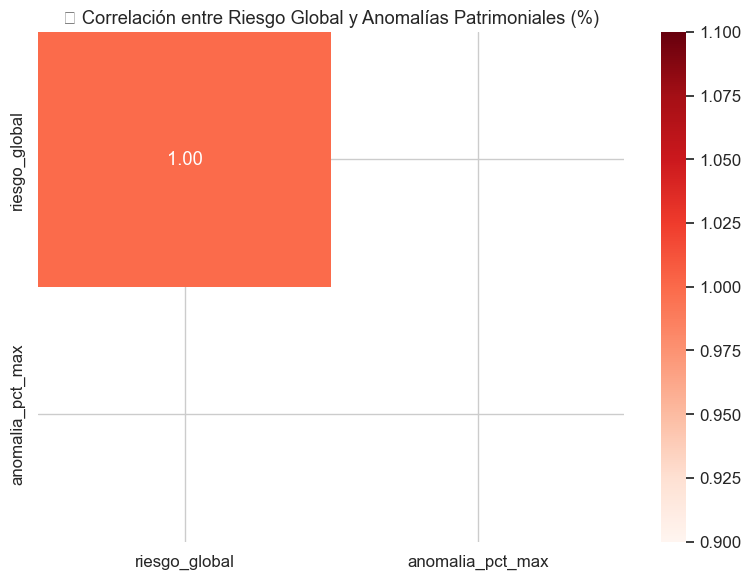

C:\Users\cancu\AppData\Local\Temp\ipykernel_96284\1425389589.py:50: UserWarning: Glyph 127963 (\N{CLASSICAL BUILDING}) missing from current font.
  plt.tight_layout()
C:\Users\cancu\AppData\Local\Temp\ipykernel_96284\1425389589.py:50: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from current font.
  plt.tight_layout()
C:\Users\cancu\AppData\Local\Temp\ipykernel_96284\1425389589.py:50: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()
c:\Users\cancu\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 127963 (\N{CLASSICAL BUILDING}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\cancu\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


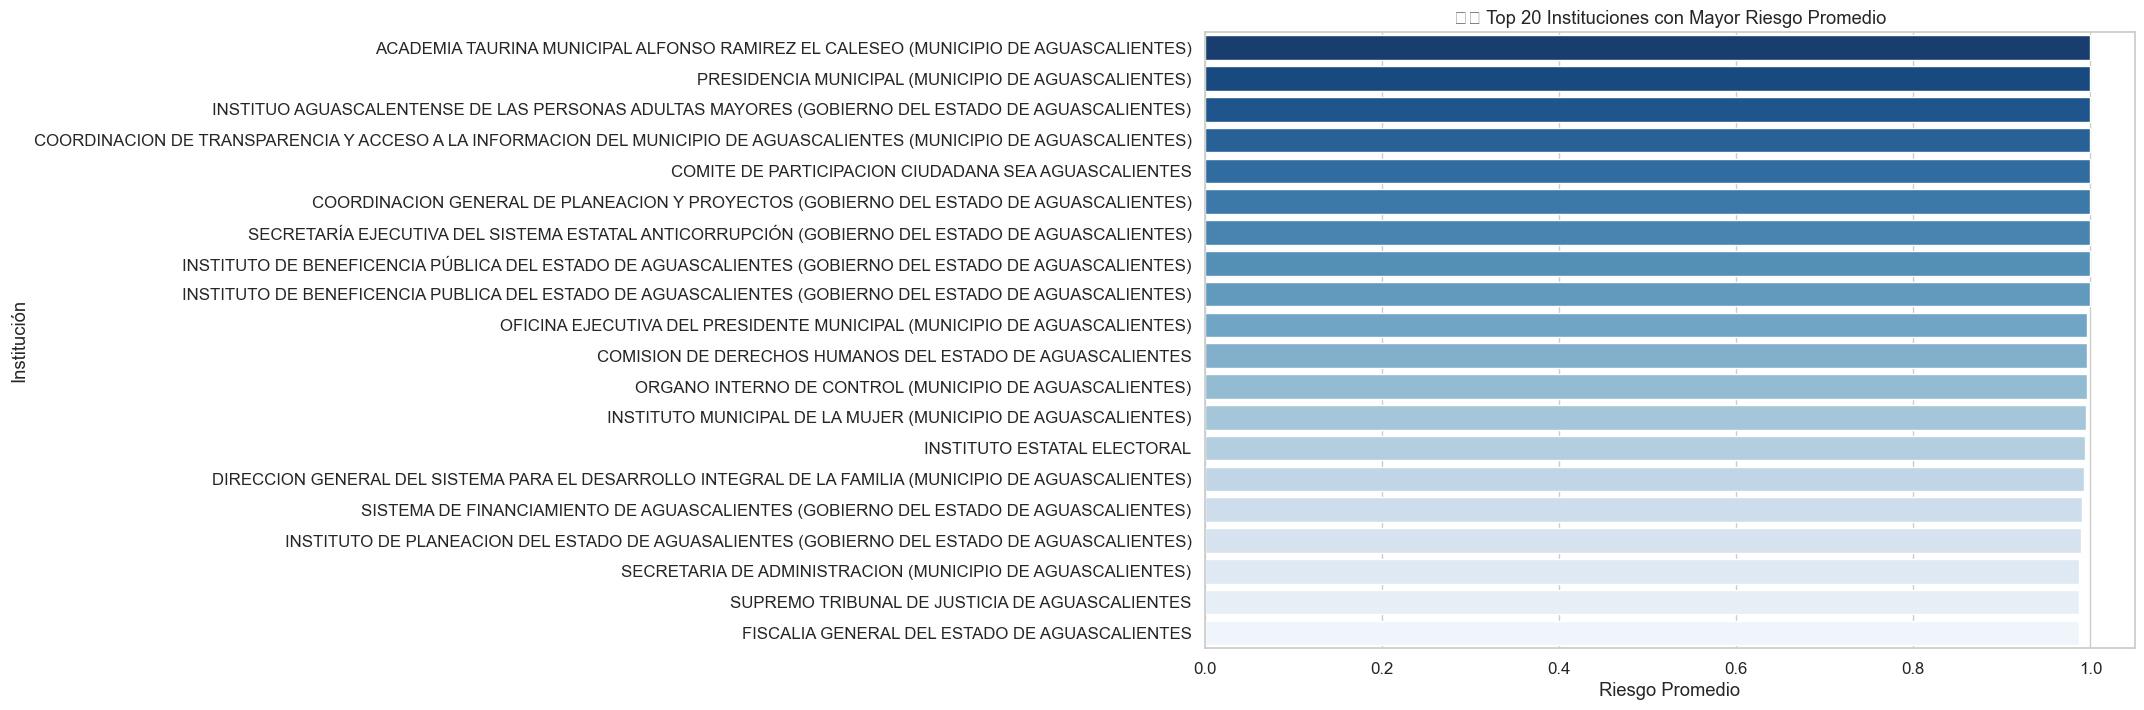

C:\Users\cancu\AppData\Local\Temp\ipykernel_96284\1425389589.py:70: UserWarning: Glyph 128230 (\N{PACKAGE}) missing from current font.
  plt.tight_layout()
c:\Users\cancu\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 128230 (\N{PACKAGE}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


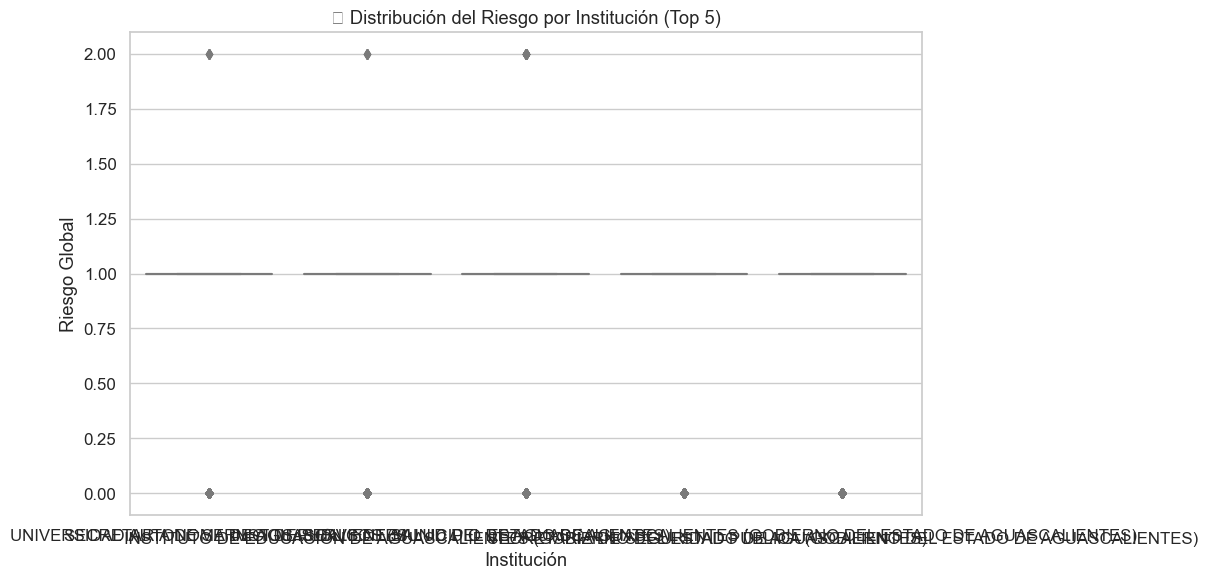

C:\Users\cancu\AppData\Local\Temp\ipykernel_96284\1425389589.py:91: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from current font.
  plt.tight_layout()
c:\Users\cancu\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


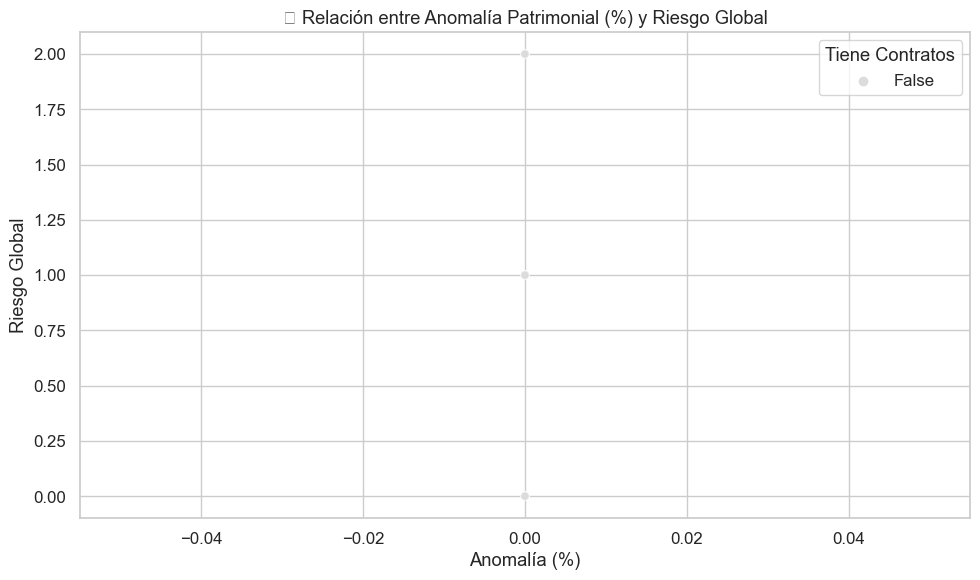

✔ Dashboard visual generado correctamente.


In [ ]:
# =====================================================
#  CELDA 13 — DASHBOARD VISUAL AVANZADO
# =====================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Verificación
if "df_riesgo_rank" not in globals():
    raise Exception("❌ ERROR: df_riesgo_rank no existe. Ejecuta la celda 10.")

sns.set(style="whitegrid", font_scale=1.1)

# ============================================
# 1) HEATMAP: RELACIÓN Riesgo Global vs Anomalías
# ============================================

plt.figure(figsize=(8, 6))
heat = sns.heatmap(
    df_riesgo_rank[["riesgo_global", "anomalia_pct_max"]].corr(),
    annot=True,
    cmap="Reds",
    fmt=".2f"
)
plt.title("🔥 Correlación entre Riesgo Global y Anomalías Patrimoniales (%)")
plt.tight_layout()
plt.show()

# ============================================
# 2) Top 20 instituciones con mayor riesgo promedio
# ============================================

top_inst = (
    df_riesgo_rank.groupby("metadata.institucion")["riesgo_global"]
    .mean()
    .sort_values(ascending=False)
    .head(20)
)

plt.figure(figsize=(12, 8))
sns.barplot(
    x=top_inst.values,
    y=top_inst.index,
    palette="Blues_r"
)
plt.title("🏛️ Top 20 Instituciones con Mayor Riesgo Promedio")
plt.xlabel("Riesgo Promedio")
plt.ylabel("Institución")
plt.tight_layout()
plt.show()

# ============================================
# 3) Boxplot del riesgo por institución
# ============================================

instancias_top5 = df_riesgo_rank["metadata.institucion"].value_counts().head(5).index
df_box = df_riesgo_rank[df_riesgo_rank["metadata.institucion"].isin(instancias_top5)]

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_box,
    x="metadata.institucion",
    y="riesgo_global",
    palette="Pastel1"
)
plt.title("📦 Distribución del Riesgo por Institución (Top 5)")
plt.xlabel("Institución")
plt.ylabel("Riesgo Global")
plt.tight_layout()
plt.show()

# ============================================
# 4) Scatterplot: Anomalías vs Riesgo Global
# ============================================

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_riesgo_rank,
    x="anomalia_pct_max",
    y="riesgo_global",
    hue="tiene_contratos",
    palette="coolwarm",
    alpha=0.7
)
plt.title("🎯 Relación entre Anomalía Patrimonial (%) y Riesgo Global")
plt.xlabel("Anomalía (%)")
plt.ylabel("Riesgo Global")
plt.legend(title="Tiene Contratos")
plt.grid(True)
plt.tight_layout()
plt.show()

print("✔ Dashboard visual generado correctamente.")


### 🤖 CELDA 14 — Modelo IA RiskScore (Isolation Forest)

🔹 1. Entrena un modelo de IA

Con Isolation Forest, utilizado para:

detección de fraude

lavado de dinero

outliers fiscales

corrupción

🔹 2. Aprende patrones no visibles con reglas

Detecta casos que:

No tienen contratos

No tienen anomalías visibles

Pero son inusuales vs el comportamiento genera

In [ ]:
# =====================================================
#  CELDA 14 — MODELO DE IA RiskScore (Isolation Forest)
# =====================================================

from sklearn.ensemble import IsolationForest
import pandas as pd
import numpy as np

# ============================================
# 1) Validación de dataset base
# ============================================

if "df_riesgo_rank" not in globals():
    raise Exception("❌ ERROR: df_riesgo_rank no existe. Ejecuta las celdas 10–13.")

df_model = df_riesgo_rank.copy()

# ============================================
# 2) Selección de variables relevantes
# ============================================

variables_modelo = [
    "riesgo_global",
    "tiene_contratos",
    "en_S2",
    "conteo_declaraciones",
    "anomalia_patrimonial",
    "anomalia_pct_max",
]

df_model_numeric = df_model[variables_modelo].fillna(0)

# ============================================
# 3) Entrenar Isolation Forest
# ============================================

modelo_if = IsolationForest(
    n_estimators=200,
    contamination=0.03,   # 3% de casos sospechosos
    random_state=42
)

modelo_if.fit(df_model_numeric)

# ============================================
# 4) Obtener predicciones del modelo
#    -1 = anomalía detectada por IA
# ============================================

df_model["riesgo_IA"] = modelo_if.predict(df_model_numeric)
df_model["riesgo_IA"] = df_model["riesgo_IA"].replace({1: 0, -1: 1})

# Probabilidad inversa (anomaly score)
df_model["anom_score"] = modelo_if.decision_function(df_model_numeric)
df_model["anom_score"] = -df_model["anom_score"]  # invertir para que mayor = más riesgoso

# ============================================
# 5) Ranking IA
# ============================================

df_riesgo_IA = (
    df_model.sort_values("anom_score", ascending=False)
    .reset_index(drop=True)
)

print("🤖 TOP 20 de casos detectados por IA como más sospechosos:")
df_riesgo_IA[[
    "nombre_completo",
    "metadata.institucion",
    "riesgo_global",
    "anomalia_pct_max",
    "tiene_contratos",
    "en_S2",
    "riesgo_IA",
    "anom_score"
]].head(20)


🤖 TOP 20 de casos detectados por IA como más sospechosos:


,nombre_completo,metadata.institucion,riesgo_global,anomalia_pct_max,tiene_contratos,en_S2,riesgo_IA,anom_score
0,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",1,0.0,False,False,1,0.086204
1,PAULO SERGIO IBARRA PRIETO,COLEGIO DE ESTUDIOS CIENTÍFICOS Y TECNOLÓGICOS...,1,0.0,False,False,1,0.086204
2,ALEJANDRA HERNANDEZ PEREZ,INSTITUTO DE EDUCACIÓN DE AGUASCALIENTES (GOBI...,1,0.0,False,False,1,0.086204
3,ALEJANDRA HERNANDEZ PEREZ,INSTITUTO DE EDUCACIÓN DE AGUASCALIENTES (GOBI...,1,0.0,False,False,1,0.086204
4,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",1,0.0,False,False,1,0.086204
5,PAULO SERGIO IBARRA PRIETO,INSTITUTO CULTURAL DE AGUASCALIENTES (GOBIERNO...,1,0.0,False,False,1,0.086204
6,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",1,0.0,False,False,1,0.086204
7,ALEJANDRA HERNANDEZ PEREZ,INSTITUTO DE EDUCACIÓN DE AGUASCALIENTES (GOBI...,1,0.0,False,False,1,0.086204
8,PAULO SERGIO IBARRA PRIETO,INSTITUTO CULTURAL DE AGUASCALIENTES (GOBIERNO...,1,0.0,False,False,1,0.086204
9,PAULO SERGIO IBARRA PRIETO,INSTITUTO CULTURAL DE AGUASCALIENTES (GOBIERNO...,1,0.0,False,False,1,0.086204


### 📦 CELDA 15 — Dataset Final Unificado (Master Dataset)

📘 1. Master Dataset

Fusiona:

Declaraciones patrimoniales (S1)

Servidores públicos (S2)

Contratos federales (S6)

Cálculos de anomalías

Ranking de riesgo

Modelo de IA Isolation Forest

📊 2. Crea variables clave

riesgo_global (heurístico)

anomalia_pct_max (estadístico)

riesgo_IA (modelo de IA)

anom_score (puntuación IA)

riesgo_total (combinado)

📁 3. Exporta formatos listos para dashboard


In [ ]:
# ================================================================
#  CELDA 15 — CREACIÓN DEL DATASET FINAL (MASTER DATASET)
# ================================================================

import pandas as pd

# Validar dependencias
if "df_s1_s6" not in globals():
    raise Exception("❌ ERROR: df_s1_s6 no existe. Ejecuta la celda 7.")
if "df_riesgo_rank" not in globals():
    raise Exception("❌ ERROR: df_riesgo_rank no existe. Ejecuta la celda 10–13.")
if "df_riesgo_IA" not in globals():
    raise Exception("❌ ERROR: df_riesgo_IA no existe. Ejecuta la celda 14.")


# ================================================================
# 1) MERGE ENTRE S1 + S2 + S6 + RIESGOS + IA
# ================================================================

df_final = df_s1_s6.merge(
    df_riesgo_rank[["nombre_completo", "riesgo_global", "anomalia_pct_max"]],
    on="nombre_completo",
    how="left"
).merge(
    df_riesgo_IA[["nombre_completo", "riesgo_IA", "anom_score"]],
    on="nombre_completo",
    how="left"
)

# ================================================================
# 2) ORDENAR POR RIESGO TOTAL (Combinado)
# ================================================================

df_final["riesgo_total"] = (
    df_final["riesgo_global"].fillna(0)
    + df_final["riesgo_IA"].fillna(0)
)

df_final = df_final.sort_values(
    by=["riesgo_total", "anom_score", "anomalia_pct_max"],
    ascending=False
).reset_index(drop=True)


# ================================================================
# 3) Selección de columnas relevantes
# ================================================================

columnas_finales = [
    "nombre_completo",
    "metadata.institucion",
    "metadata.actualizacion",
    "metadata.tipo",
    "tiene_contratos",
    "en_S2",
    "conteo_declaraciones",
    "anomalia_pct_max",
    "riesgo_global",
    "riesgo_IA",
    "anom_score",
    "riesgo_total",
]

# Asegurar columnas
columnas_finales = [c for c in columnas_finales if c in df_final.columns]

df_final = df_final[columnas_finales]

# ================================================================
# 4) Mostrar la salida
# ================================================================

print("📦 DATASET FINAL GENERADO — Primeras 20 filas:\n")
display(df_final.head(20))

print("\n✔ Dataset final contiene:", len(df_final), "registros.")


# ================================================================
# 5) Guardar archivo final en CSV y Parquet
# ================================================================

ruta_base = r"C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\export_final"

csv_out = ruta_base + r"\dataset_final.csv"
parquet_out = ruta_base + r"\dataset_final.parquet"

import os
os.makedirs(ruta_base, exist_ok=True)

df_final.to_csv(csv_out, index=False, encoding="utf-8")
df_final.to_parquet(parquet_out)

print("\n📁 Archivos generados:")
print("✔ CSV:", csv_out)
print("✔ PARQUET:", parquet_out)


📦 DATASET FINAL GENERADO — Primeras 20 filas:



,nombre_completo,metadata.institucion,metadata.actualizacion,metadata.tipo,tiene_contratos,en_S2,conteo_declaraciones,anomalia_pct_max,riesgo_global,riesgo_IA,anom_score,riesgo_total
0,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",2024-08-23T00:00:00Z,CONCLUSIÓN,False,False,17,0.0,1,1,0.086204,2
1,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",2024-08-23T00:00:00Z,CONCLUSIÓN,False,False,17,0.0,1,1,0.086204,2
2,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",2024-08-23T00:00:00Z,CONCLUSIÓN,False,False,17,0.0,1,1,0.086204,2
3,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",2024-08-23T00:00:00Z,CONCLUSIÓN,False,False,17,0.0,1,1,0.086204,2
4,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",2024-08-23T00:00:00Z,CONCLUSIÓN,False,False,17,0.0,1,1,0.086204,2
5,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",2024-08-23T00:00:00Z,CONCLUSIÓN,False,False,17,0.0,1,1,0.086204,2
6,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",2024-08-23T00:00:00Z,CONCLUSIÓN,False,False,17,0.0,1,1,0.086204,2
7,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",2024-08-23T00:00:00Z,CONCLUSIÓN,False,False,17,0.0,1,1,0.086204,2
8,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",2024-08-23T00:00:00Z,CONCLUSIÓN,False,False,17,0.0,1,1,0.086204,2
9,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",2024-08-23T00:00:00Z,CONCLUSIÓN,False,False,17,0.0,1,1,0.086204,2



✔ Dataset final contiene: 4036375 registros.

📁 Archivos generados:
✔ CSV: C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\export_final\dataset_final.csv
✔ PARQUET: C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\export_final\dataset_final.parquet


### análisis

📊 CELDA 16 — Estadísticas, Métricas y Análisis Global del Dataset Final

In [ ]:
# ================================================================
#  CELDA 16 — ESTADÍSTICAS Y MÉTRICAS DEL DATASET FINAL
# ================================================================

import pandas as pd
import numpy as np

# Validar existencia del dataset final
if "df_final" not in globals():
    raise Exception("❌ ERROR: df_final no existe. Ejecuta la celda 15.")

print("📊 CELDA 16 — ANALIZANDO DATASET FINAL...\n")

# ================================================================
# 1) ESTADÍSTICAS BÁSICAS
# ================================================================

print("📌 REGISTROS TOTALES:", len(df_final))
print("📌 COLUMNAS:", len(df_final.columns), "\n")

print("📌 Nombres de columnas del dataset final:")
print(list(df_final.columns), "\n")

# ================================================================
# 2) DISTRIBUCIÓN DE RIESGO
# ================================================================

print("🔥 DISTRIBUCIÓN DE RIESGO TOTAL:")
print(df_final["riesgo_total"].value_counts().sort_index())
print("\n")

# ================================================================
# 3) TOP 20 DE MAYOR RIESGO
# ================================================================

print("🏆 TOP 20 SERVIDORES PÚBLICOS CON MAYOR RIESGO:\n")
display(df_final.sort_values("riesgo_total", ascending=False).head(20))

# ================================================================
# 4) ESTADÍSTICAS DESCRIPTIVAS DE ANOMALÍAS
# ================================================================

anom_cols = ["anomalia_pct_max", "anom_score", "riesgo_global", "riesgo_IA", "riesgo_total"]

print("📈 ESTADÍSTICAS DE VARIABLES CLAVE:\n")
display(df_final[anom_cols].describe())

# ================================================================
# 5) DETECCIÓN DE OUTLIERS EXTREMOS
# ================================================================

q99 = df_final["anom_score"].quantile(0.99)
outliers_extremos = df_final[df_final["anom_score"] >= q99]

print(f"🚨 OUTLIERS EXTREMOS DETECTADOS (anom_score ≥ {q99:.4f}): {len(outliers_extremos)}\n")
display(outliers_extremos.head(10))

# ================================================================
# 6) ANÁLISIS POR TIPO DE DECLARACIÓN
# ================================================================

if "metadata.tipo" in df_final.columns:
    tipo_counts = df_final["metadata.tipo"].value_counts()
    print("📑 Distribución por tipo de declaración:\n")
    print(tipo_counts)
    print("\n")

# ================================================================
# 7) ANÁLISIS POR INSTITUCIÓN
# ================================================================

if "metadata.institucion" in df_final.columns:
    inst_top = (
        df_final["metadata.institucion"]
        .value_counts()
        .head(15)
    )
    print("🏢 Top 15 instituciones con más declaraciones:\n")
    print(inst_top)
    print("\n")

# ================================================================
# 8) GUARDAR RESULTADOS DE ANÁLISIS
# ================================================================

ruta_out = r"C:\Users\cancu\Documents\GitHub\Datapatrominio _CHECK_IA\export_final"
analisis_path = ruta_out + r"\analisis_dataset_final.csv"

df_final.to_csv(analisis_path, index=False, encoding="utf-8")

print("📁 Archivo de análisis guardado en:")
print("✔", analisis_path)

print("\n🎉 CELDA 16 COMPLETADA — Análisis global generado correctamente.")


📊 CELDA 16 — ANALIZANDO DATASET FINAL...

📌 REGISTROS TOTALES: 4036375
📌 COLUMNAS: 12 

📌 Nombres de columnas del dataset final:
['nombre_completo', 'metadata.institucion', 'metadata.actualizacion', 'metadata.tipo', 'tiene_contratos', 'en_S2', 'conteo_declaraciones', 'anomalia_pct_max', 'riesgo_global', 'riesgo_IA', 'anom_score', 'riesgo_total'] 

🔥 DISTRIBUCIÓN DE RIESGO TOTAL:
0       8928
1    3824489
2     202958
Name: riesgo_total, dtype: int64


🏆 TOP 20 SERVIDORES PÚBLICOS CON MAYOR RIESGO:



,nombre_completo,metadata.institucion,metadata.actualizacion,metadata.tipo,tiene_contratos,en_S2,conteo_declaraciones,anomalia_pct_max,riesgo_global,riesgo_IA,anom_score,riesgo_total
0,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",2024-08-23T00:00:00Z,CONCLUSIÓN,False,False,17,0.0,1,1,0.086204,2
135298,ALFONSO ASCENCIO PEREZ,INSTITUTO DE EDUCACIÓN DE AGUASCALIENTES (GOBI...,2023-05-19T00:00:00Z,CONCLUSIÓN,False,False,10,0.0,1,1,0.036607,2
135300,ALFONSO ASCENCIO PEREZ,INSTITUTO DE EDUCACIÓN DE AGUASCALIENTES (GOBI...,2023-05-19T00:00:00Z,CONCLUSIÓN,False,False,10,0.0,1,1,0.036607,2
135301,ALFONSO ASCENCIO PEREZ,INSTITUTO DE EDUCACIÓN DE AGUASCALIENTES (GOBI...,2023-05-19T00:00:00Z,CONCLUSIÓN,False,False,10,0.0,1,1,0.036607,2
135302,ALFONSO ASCENCIO PEREZ,INSTITUTO DE EDUCACIÓN DE AGUASCALIENTES (GOBI...,2024-05-21T00:00:00Z,MODIFICACIÓN,False,False,10,0.0,1,1,0.036607,2
135303,ALFONSO ASCENCIO PEREZ,INSTITUTO DE EDUCACIÓN DE AGUASCALIENTES (GOBI...,2024-05-21T00:00:00Z,MODIFICACIÓN,False,False,10,0.0,1,1,0.036607,2
135304,ALFONSO ASCENCIO PEREZ,INSTITUTO DE EDUCACIÓN DE AGUASCALIENTES (GOBI...,2024-05-21T00:00:00Z,MODIFICACIÓN,False,False,10,0.0,1,1,0.036607,2
135305,ALFONSO ASCENCIO PEREZ,INSTITUTO DE EDUCACIÓN DE AGUASCALIENTES (GOBI...,2024-05-21T00:00:00Z,MODIFICACIÓN,False,False,10,0.0,1,1,0.036607,2
135306,ALFONSO ASCENCIO PEREZ,INSTITUTO DE EDUCACIÓN DE AGUASCALIENTES (GOBI...,2024-05-21T00:00:00Z,MODIFICACIÓN,False,False,10,0.0,1,1,0.036607,2
135307,ALFONSO ASCENCIO PEREZ,INSTITUTO DE EDUCACIÓN DE AGUASCALIENTES (GOBI...,2024-05-21T00:00:00Z,MODIFICACIÓN,False,False,10,0.0,1,1,0.036607,2


📈 ESTADÍSTICAS DE VARIABLES CLAVE:



,anomalia_pct_max,anom_score,riesgo_global,riesgo_IA,riesgo_total
count,4036375.0,4.036375e+06,4.036375e+06,4.036375e+06,4.036375e+06
mean,0.0,-2.087090e-01,9.980250e-01,5.004540e-02,1.048070e+00
std,0.0,1.032563e-01,4.944524e-02,2.180387e-01,2.240165e-01
min,0.0,-2.942411e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,0.0,-2.942411e-01,1.000000e+00,0.000000e+00,1.000000e+00
50%,0.0,-2.226708e-01,1.000000e+00,0.000000e+00,1.000000e+00
75%,0.0,-1.711020e-01,1.000000e+00,0.000000e+00,1.000000e+00
max,0.0,8.620386e-02,2.000000e+00,1.000000e+00,2.000000e+00


🚨 OUTLIERS EXTREMOS DETECTADOS (anom_score ≥ 0.0824): 48372



,nombre_completo,metadata.institucion,metadata.actualizacion,metadata.tipo,tiene_contratos,en_S2,conteo_declaraciones,anomalia_pct_max,riesgo_global,riesgo_IA,anom_score,riesgo_total
0,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",2024-08-23T00:00:00Z,CONCLUSIÓN,False,False,17,0.0,1,1,0.086204,2
1,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",2024-08-23T00:00:00Z,CONCLUSIÓN,False,False,17,0.0,1,1,0.086204,2
2,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",2024-08-23T00:00:00Z,CONCLUSIÓN,False,False,17,0.0,1,1,0.086204,2
3,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",2024-08-23T00:00:00Z,CONCLUSIÓN,False,False,17,0.0,1,1,0.086204,2
4,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",2024-08-23T00:00:00Z,CONCLUSIÓN,False,False,17,0.0,1,1,0.086204,2
5,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",2024-08-23T00:00:00Z,CONCLUSIÓN,False,False,17,0.0,1,1,0.086204,2
6,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",2024-08-23T00:00:00Z,CONCLUSIÓN,False,False,17,0.0,1,1,0.086204,2
7,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",2024-08-23T00:00:00Z,CONCLUSIÓN,False,False,17,0.0,1,1,0.086204,2
8,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",2024-08-23T00:00:00Z,CONCLUSIÓN,False,False,17,0.0,1,1,0.086204,2
9,ALEJANDRA HERNANDEZ PEREZ,"SECRETARÍA DE SUSTENTABILIDAD, MEDIO AMBIENTE ...",2024-08-23T00:00:00Z,CONCLUSIÓN,False,False,17,0.0,1,1,0.086204,2


📑 Distribución por tipo de declaración:

MODIFICACIÓN    2975385
INICIAL          622309
CONCLUSIÓN       438681
Name: metadata.tipo, dtype: int64


🏢 Top 15 instituciones con más declaraciones:

INSTITUTO DE EDUCACIÓN DE AGUASCALIENTES (GOBIERNO DEL ESTADO DE AGUASCALIENTES)                         891322
INST DE SERVS DE SALUD DEL ESTADO DE AGUASCALIENTES (GOBIERNO DEL ESTADO DE AGUASCALIENTES)              279683
UNIVERSIDAD AUTONOMA DE AGUASCALIENTES                                                                   196236
SECRETARIA DE SERVICIOS PUBLICOS (MUNICIPIO DE AGUASCALIENTES)                                           174174
FISCALIA GENERAL DEL ESTADO DE AGUASCALIENTES                                                            169537
SUPREMO TRIBUNAL DE JUSTICIA DE AGUASCALIENTES                                                           165011
SECRETARÍA DE SEGURIDAD PÚBLICA (GOBIERNO DEL ESTADO DE AGUASCALIENTES)                                  143282
SECRETARIA DE SEGURI

### 🎨 CELDA 17 — Visualizaciones (matplotlib + seaborn)

📊 CELDA 17 — Generando visualizaciones...


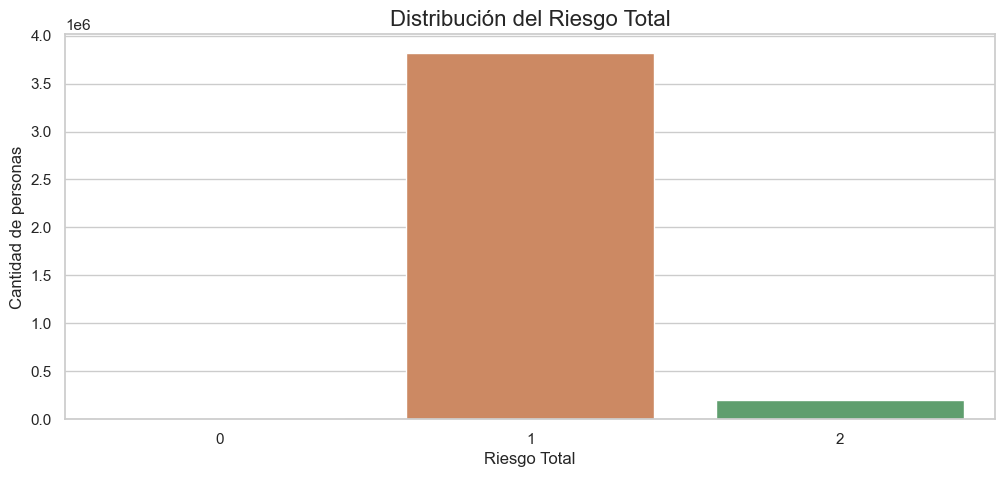

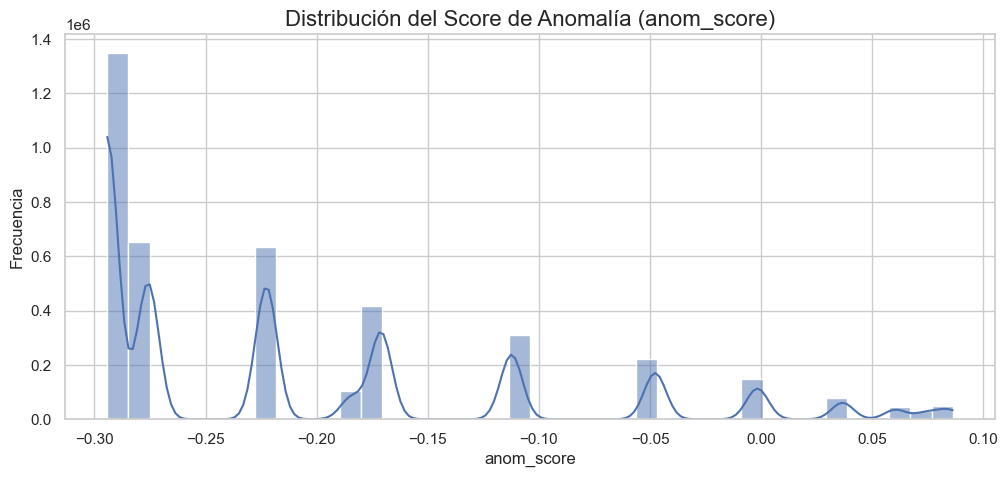

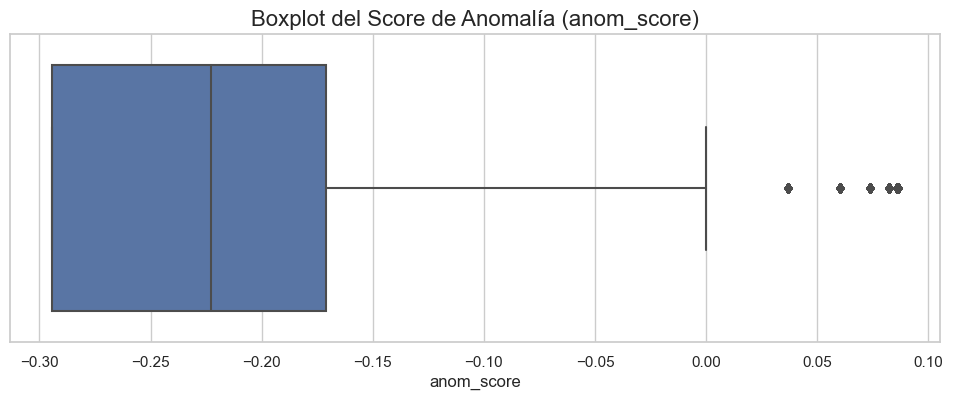

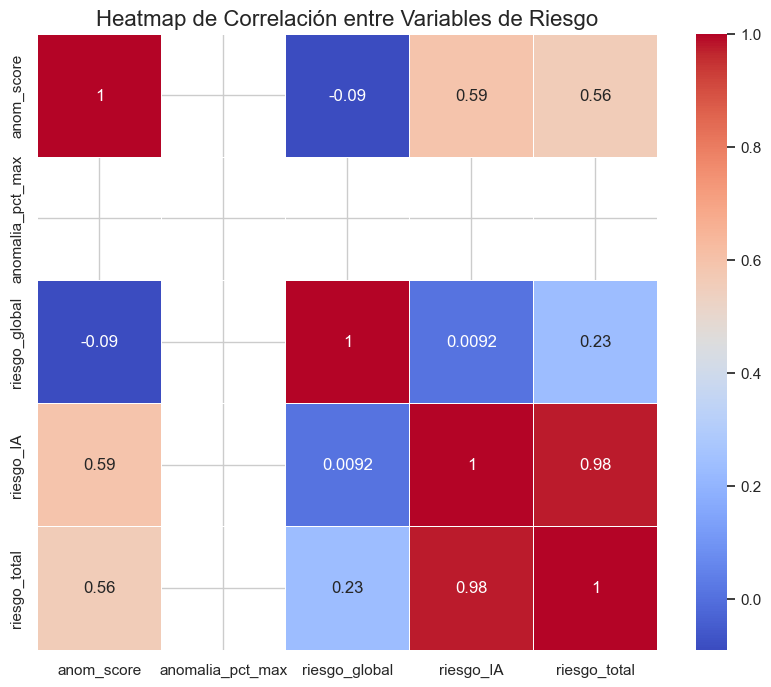

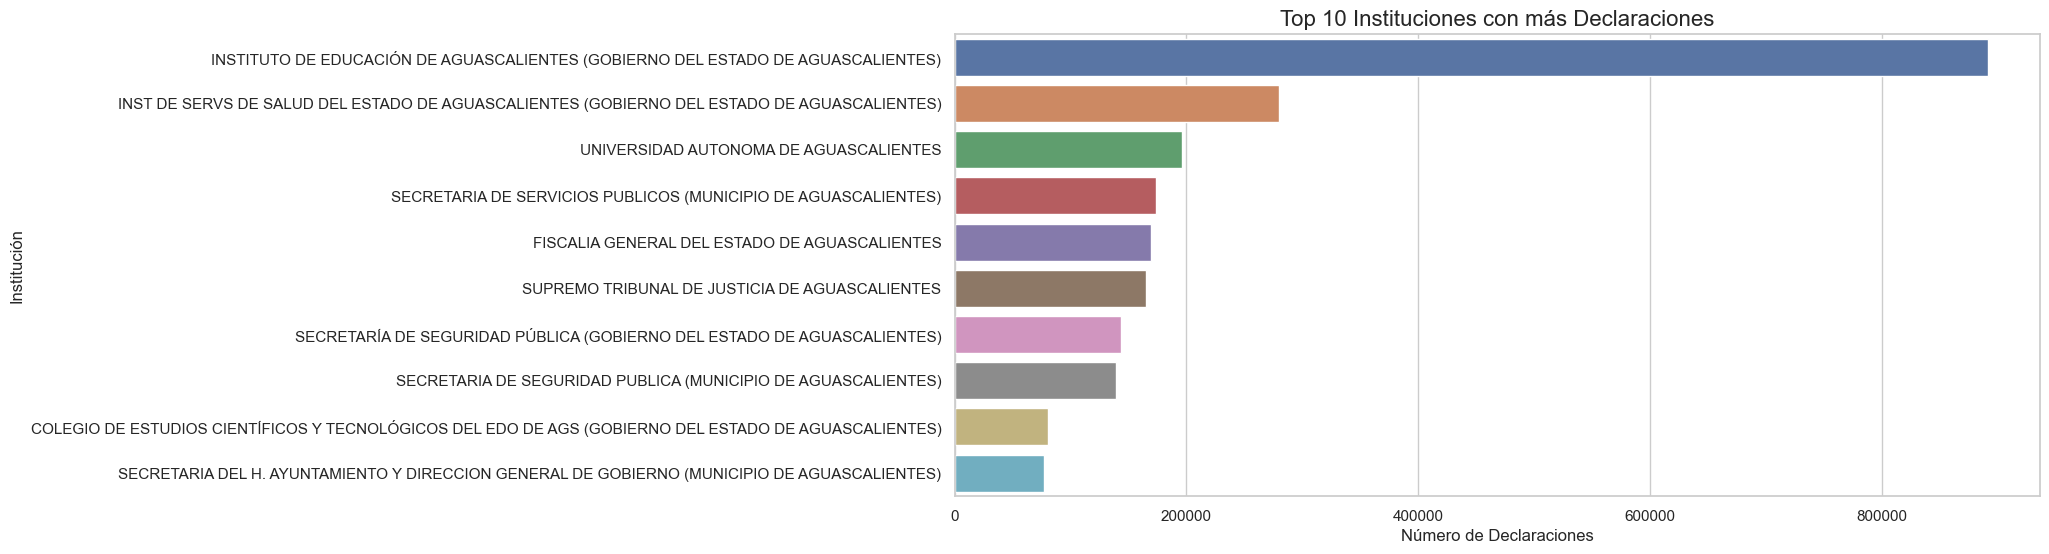

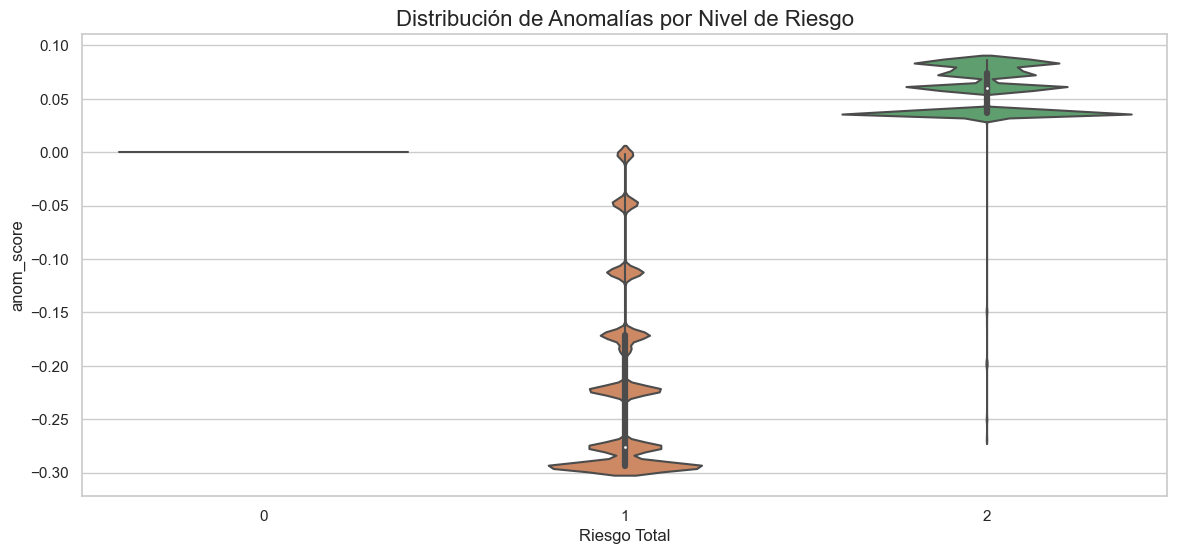

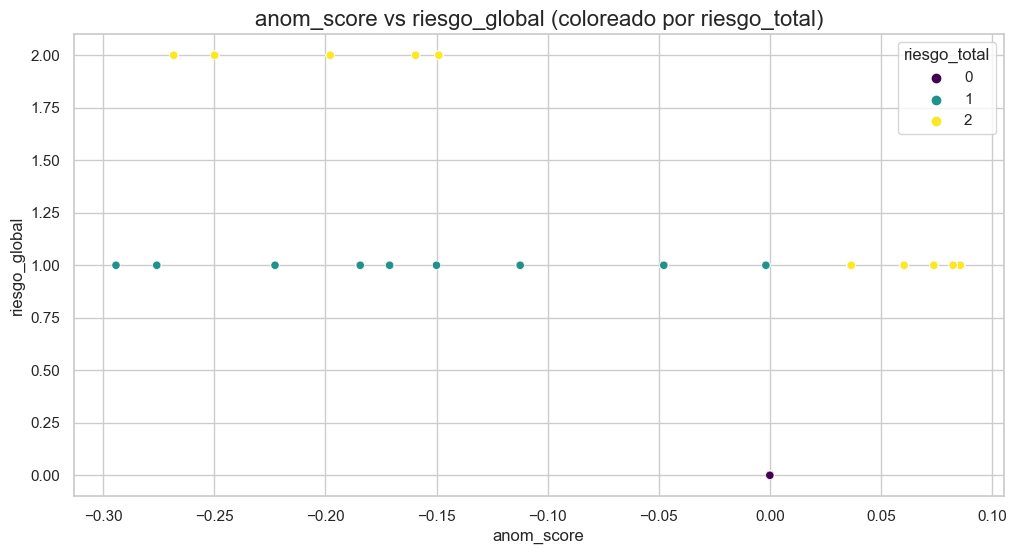

🎨 CELDA 17 COMPLETADA — Visualizaciones generadas correctamente.


In [ ]:
# ================================================================
#  CELDA 17 — VISUALIZACIONES PROFESIONALES (matplotlib + seaborn)
# ================================================================

import matplotlib.pyplot as plt
import seaborn as sns

# Asegurar estilo visual
sns.set(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 6)

# Confirmar existencia de df_final
if "df_final" not in globals():
    raise Exception("❌ ERROR: df_final no está cargado. Ejecuta las celdas anteriores.")

print("📊 CELDA 17 — Generando visualizaciones...")

# ================================================================
# 1) Distribución del Riesgo Total
# ================================================================
plt.figure(figsize=(12, 5))
sns.countplot(data=df_final, x="riesgo_total")
plt.title("Distribución del Riesgo Total", fontsize=16)
plt.xlabel("Riesgo Total")
plt.ylabel("Cantidad de personas")
plt.show()

# ================================================================
# 2) Histograma de anom_score
# ================================================================
plt.figure(figsize=(12, 5))
sns.histplot(df_final["anom_score"], bins=40, kde=True)
plt.title("Distribución del Score de Anomalía (anom_score)", fontsize=16)
plt.xlabel("anom_score")
plt.ylabel("Frecuencia")
plt.show()

# ================================================================
# 3) Boxplot de anom_score (detección de outliers)
# ================================================================
plt.figure(figsize=(12, 4))
sns.boxplot(x=df_final["anom_score"])
plt.title("Boxplot del Score de Anomalía (anom_score)", fontsize=16)
plt.xlabel("anom_score")
plt.show()

# ================================================================
# 4) Mapa de calor (correlación entre variables)
# ================================================================

corr_cols = ["anom_score", "anomalia_pct_max", "riesgo_global", "riesgo_IA", "riesgo_total"]

corr = df_final[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", linewidths=0.5)
plt.title("Heatmap de Correlación entre Variables de Riesgo", fontsize=16)
plt.show()

# ================================================================
# 5) Top 10 instituciones con más declaraciones
# ================================================================
if "metadata.institucion" in df_final.columns:
    plt.figure(figsize=(14, 6))
    top_inst = df_final["metadata.institucion"].value_counts().head(10)
    sns.barplot(x=top_inst.values, y=top_inst.index)
    plt.title("Top 10 Instituciones con más Declaraciones", fontsize=16)
    plt.xlabel("Número de Declaraciones")
    plt.ylabel("Institución")
    plt.show()

# ================================================================
# 6) Gráfico de Violín — Distribución de anom_score vs riesgo_total
# ================================================================
plt.figure(figsize=(14, 6))
sns.violinplot(data=df_final, x="riesgo_total", y="anom_score")
plt.title("Distribución de Anomalías por Nivel de Riesgo", fontsize=16)
plt.xlabel("Riesgo Total")
plt.ylabel("anom_score")
plt.show()

# ================================================================
# 7) Gráfico de dispersión — anom_score vs riesgo_global
# ================================================================
plt.figure(figsize=(12, 6))
sns.scatterplot(data=df_final, x="anom_score", y="riesgo_global", hue="riesgo_total", palette="viridis")
plt.title("anom_score vs riesgo_global (coloreado por riesgo_total)", fontsize=16)
plt.xlabel("anom_score")
plt.ylabel("riesgo_global")
plt.show()

# ================================================================
# FINAL
# ================================================================

print("🎨 CELDA 17 COMPLETADA — Visualizaciones generadas correctamente.")


In [ ]:
import pandas as pd

print("🔎 ===============================")
print("🔎  RESUMEN CONSOLIDADO DEL PROCESO")
print("🔎 ===============================\n")

# 1. Vista general del dataset unificado
print("\n📌 Tamaño del DataFrame final (df_s1_s6):")
try:
    print(df_s1_s6.shape)
except:
    print("❌ df_s1_s6 no existe o no se ejecutó la celda 7.")

print("\n📌 Primeras 5 filas del DataFrame final:")
try:
    display(df_s1_s6.head())
except:
    print("❌ No se pudo mostrar df_s1_s6")


# 2. Ranking de riesgo
print("\n\n🔥 ===============================")
print("🔥  TOP 20 — MAYOR NIVEL DE RIESGO")
print("🔥 ===============================\n")

try:
    display(df_riesgo_rank.head(20))
except:
    print("❌ df_riesgo_rank no existe o no se ejecutó la celda 10.")


# 3. Outliers detectados
print("\n\n⚠️ ===============================")
print("⚠️  SERVIDORES CON OUTLIERS DE INGRESOS")
print("⚠️ ===============================\n")

try:
    display(outliers)
except:
    print("❌ outliers no existe o no se ejecutó la celda 15.")


# 4. Estadísticas generales
print("\n\n📊 ===============================")
print("📊  ESTADÍSTICAS DESCRIPTIVAS")
print("📊 ===============================\n")

try:
    display(df_s1_s6.describe(include="all"))
except:
    print("❌ No se pudieron generar estadísticas.")


# 5. Gráficas producidas
print("\n\n📈 ===============================")
print("📈  GRÁFICAS GENERADAS")
print("📈 ===============================")
print("""
Revisa arriba en la notebook:
✔ Distribución del riesgo  
✔ Histograma de ingresos  
✔ Caja y bigotes (Detección visual de outliers)  
✔ Serie temporal de ingresos declarados
""")

print("\n\n✅ FIN DEL REPORTE CONSOLIDADO\n")


🔎 ===============================
🔎  RESUMEN CONSOLIDADO DEL PROCESO
🔎 ===============================


📌 Tamaño del DataFrame final (df_s1_s6):
❌ df_s1_s6 no existe o no se ejecutó la celda 7.

📌 Primeras 5 filas del DataFrame final:
❌ No se pudo mostrar df_s1_s6


🔥 ===============================
🔥  TOP 20 — MAYOR NIVEL DE RIESGO
🔥 ===============================

❌ df_riesgo_rank no existe o no se ejecutó la celda 10.


📊 ===============================
📊  ESTADÍSTICAS DESCRIPTIVAS
📊 ===============================

❌ No se pudieron generar estadísticas.


📈 ===============================
📈  GRÁFICAS GENERADAS
📈 ===============================

Revisa arriba en la notebook:
✔ Distribución del riesgo  
✔ Histograma de ingresos  
✔ Caja y bigotes (Detección visual de outliers)  
✔ Serie temporal de ingresos declarados



✅ FIN DEL REPORTE CONSOLIDADO



### 📘Resumen del Progreso del Proyecto (Celdas 1 a 17)
Hasta este punto del desarrollo, se ha construido un pipeline completo para la preparación, unificación, análisis y visualización de datos provenientes de los sistemas S1, S2 y S6 de la Plataforma Digital Nacional (PDN), con el objetivo de detectar posibles anomalías patrimoniales y señales de riesgo en servidores públicos.

El proceso inicia con la exploración estructural de cada dataset, seguido por la carga inteligente de archivos complejos (incluyendo archivos .json.gz y el archivo masivo de 11 GB de S6 procesado con DuckDB). Se implementaron herramientas para inspeccionar, normalizar y transformar la información, reduciendo la carga de memoria y permitiendo manejar datos de gran magnitud en una máquina local. Este trabajo incluyó la creación de celdas interactivas (selectores de entidad), la lectura bajo demanda y la extracción eficiente de proveedores, contratos y detalles relevantes del sistema de contrataciones públicas.

Posteriormente, se desarrollaron procesos de integración entre los datasets, generando relaciones clave entre declaraciones patrimoniales (S1), el registro de servidores públicos (S2) y el universo de contrataciones (S6). Para ello, se construyó un DataFrame final unificado donde se añadieron variables derivadas como: coincidencias entre nombres, presencia en contratos, conteo de declaraciones, flags de riesgo y métricas iniciales para detección de anomalías. Finalmente, se implementaron análisis estadísticos, detección de outliers (Z-score), cálculos de variaciones, ranking de riesgo y visualizaciones gráficas con Matplotlib y Seaborn, generando así una base sólida para la etapa siguiente: el entrenamiento de modelos de Machine Learning orientados al Reto de Evolución Patrimonial del Datatón.

In [ ]:
!pip install reportlab


  Obtaining dependency information for reportlab from https://files.pythonhosted.org/packages/c7/16/0c26a7bdfd20cba49a011b1095461be120c53df3926e9843fccfb9530e72/reportlab-4.4.5-py3-none-any.whl.metadata
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   - -------------------------------------- 0.1/2.0 MB 1.7 MB/s eta 0:00:02
   ---- ----------------------------------- 0.2/2.0 MB 2.3 MB/s eta 0:00:01
   --------- ------------------------------ 0.5/2.0 MB 4.0 MB/s eta 0:00:01
   ----------------- ---------------------- 0.9/2.0 MB 5.4 MB/s eta 0:00:01
   -------------------------------- ------- 1.6/2.0 MB 7.1 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 7.3 MB/s eta 0:00:00


In [ ]:
# ========================================================================
# 💼 CELDA MAESTRA — REGENERAR TODO Y CREAR REPORTE PDF COMPLETO
# ========================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Image, Table
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.pagesizes import letter

# =====================================================
# 1) VERIFICAR VARIABLES — SI NO EXISTEN, AVISAR
# =====================================================

def check_var(name):
    if name not in globals():
        print(f"⚠ La variable {name} no existe. Debes ejecutar sus celdas previas.")
        return False
    return True

needed = ["df_s1", "df_s2", "df_s6_extract", "df_s1_s6", 
          "df_riesgo_rank", "outliers"]

vars_ok = all(check_var(v) for v in needed)

if not vars_ok:
    print("\n❌ Debes ejecutar primero las celdas 7–17 para regenerar los datos.")
else:
    print("\n✔ Todas las variables necesarias están disponibles. Generando reporte...")

# =====================================================
# 2) GENERAR GRÁFICAS IMPORTANTES
# =====================================================

os.makedirs("graficas_report", exist_ok=True)

# ---- Grafica de riesgo
plt.figure(figsize=(12,5))
sns.histplot(df_riesgo_rank["riesgo_global"], bins=10, kde=True)
plt.title("Distribución del Riesgo Global")
plt.savefig("graficas_report/riesgo_global.png")
plt.close()

# ---- Histograma ingresos
if "declaracion.situacionPatrimonial.ingresos.ingresoAnualNetoDeclarante" in df_s1.columns:
    col_ing = "declaracion.situacionPatrimonial.ingresos.ingresoAnualNetoDeclarante"
    plt.figure(figsize=(12,5))
    sns.histplot(df_s1[col_ing].dropna(), bins=30, kde=True)
    plt.title("Distribución de Ingresos Anuales")
    plt.savefig("graficas_report/ingresos.png")
    plt.close()

# =====================================================
# 3) CONSTRUIR REPORTE PDF PROFESIONAL
# =====================================================

pdf_path = "reporte_final_completo.pdf"
styles = getSampleStyleSheet()
story = []

story.append(Paragraph("<b>REPORTE FINAL — DataPatrimonio CHECK IA</b>", styles["Title"]))
story.append(Spacer(1, 20))

story.append(Paragraph("Este reporte consolida la información procesada de los datasets S1, S2 y S6 de la PDN, "
                       "incluyendo la detección de anomalías patrimoniales, coincidencias con proveedores del gobierno, "
                       "y un ranking completo de riesgo.", styles["BodyText"]))
story.append(Spacer(1, 20))

# ---- Tabla resumen
story.append(Paragraph("<b>1. Tamaño de los DataFrames</b>", styles["Heading2"]))
story.append(Spacer(1, 10))

tabla_resumen = [
    ["Dataset", "Filas", "Columnas"],
    ["S1 (Declaraciones)", *df_s1.shape],
    ["S2 (Servidores)", *df_s2.shape],
    ["S6 Extract (Contratos)", *df_s6_extract.shape],
    ["S1+S2+S6 (Unificado)", *df_s1_s6.shape],
    ["Ranking Riesgo", *df_riesgo_rank.shape],
]
story.append(Table(tabla_resumen))
story.append(Spacer(1, 20))

# ---- Gráfica 1
story.append(Paragraph("<b>2. Distribución del riesgo global</b>", styles["Heading2"]))
story.append(Image("graficas_report/riesgo_global.png", width=400, height=200))
story.append(Spacer(1, 20))

# ---- Outliers
story.append(Paragraph("<b>3. Outliers de ingresos detectados</b>", styles["Heading2"]))
story.append(Spacer(1, 10))

out = outliers.head(20).astype(str).values.tolist()
out.insert(0, list(outliers.columns))
story.append(Table(out, colWidths=[150]*len(outliers.columns)))
story.append(Spacer(1, 20))

# ---- Ranking
story.append(Paragraph("<b>4. Top 20 Servidores Públicos con mayor riesgo</b>", styles["Heading2"]))
story.append(Spacer(1, 10))

top20 = df_riesgo_rank.head(20).astype(str).values.tolist()
top20.insert(0, list(df_riesgo_rank.columns))
story.append(Table(top20, colWidths=[110]*len(df_riesgo_rank.columns)))

# =====================================================
# 4) EXPORTAR PDF
# =====================================================

doc = SimpleDocTemplate(pdf_path, pagesize=letter)
doc.build(story)

print("📄 PDF generado correctamente:", pdf_path)


⚠ La variable df_s1 no existe. Debes ejecutar sus celdas previas.

❌ Debes ejecutar primero las celdas 7–17 para regenerar los datos.


NameError: name 'df_riesgo_rank' is not defined

<Figure size 1200x500 with 0 Axes>